# Time Series Practice 3

## Phase 0 — Problem Definition

### 5W1H

| Thành phần | Nội dung |
|---|---|
| **What** | Dự báo mức tiêu thụ điện theo giờ với target `AEP_MW`. |
| **Why** | Đánh giá Machine Learning cho dự báo giờ kế tiếp và kiểm tra độ suy giảm khi dự báo recursive 24 giờ. |
| **Who** | Người phân tích dữ liệu và đơn vị cần theo dõi hoặc dự báo nhu cầu điện. |
| **Where** | [Kaggle — AEP Hourly Energy Consumption](https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption?select=AEP_hourly.csv); source không cung cấp timezone hoặc UTC offset. |
| **When** | `2004-10-01 01:00:00` → `2018-08-03 00:00:00`, tần suất theo giờ. |
| **How** | Data Preparation → Temporal Split → TRAIN-only EDA → Feature Engineering → X/y → Model Selection → Final Evaluation → Error Analysis → Conclusion. |

### Forecasting Contract

| Nội dung | Quy ước |
|---|---|
| Bài toán chính | One-step forecast `y(t+1)` — yêu cầu chính của đề |
| Bài tập nâng cao | Multi-step forecasting — triển khai bằng Recursive 24-hour |
| Forecast origin | Chỉ sử dụng thông tin đã có tại thời điểm dự báo |
| Baselines | Persistence `y(t-1)` và Seasonal Naive `y(t-24h)` |
| Model selection | 5 expanding-window folds trên Development, không shuffle |
| Final evaluation | Historical Re-evaluation Holdout |
| Metrics | MAE chính, RMSE phụ |

In [1]:
import json

import pandas as pd
from IPython.display import Image as DisplayImage, Markdown, display
from practice_3_v2.data.data_preparation import calculate_sha256
from practice_3_v2.visualization.presentation_artifacts import load_presentation_artifacts
from practice_3_v2.visualization.table_style import SELECTED_ROW_STYLE, style_table

artifacts = load_presentation_artifacts()
project_root = artifacts.project_root
prepared_data = artifacts.prepared_data
phase_01_audit = artifacts.phase_01_audit
phase_02_audit = artifacts.phase_02_audit
phase_03_audit = artifacts.phase_03_audit
phase_03_presentation = artifacts.phase_03_presentation
phase_04_audit = artifacts.phase_04_audit
phase_04_presentation = artifacts.phase_04_presentation
phase_05_audit = artifacts.phase_05_audit
phase_05_presentation = artifacts.phase_05_presentation
phase_05_conversion_figure_path = artifacts.phase_05_conversion_figure_path
phase_06_cv = artifacts.phase_06_cv
phase_06_lock = artifacts.phase_06_lock
phase_06_training_diagnostics = artifacts.phase_06_training_diagnostics
phase_06_supplemental_linear = artifacts.phase_06_supplemental_linear
phase_06_supplemental_lag = artifacts.phase_06_supplemental_lag
phase_06_figure_path = artifacts.phase_06_figure_path
phase_06_tuning_figure_path = artifacts.phase_06_tuning_figure_path
phase_06_fold_figure_path = artifacts.phase_06_fold_figure_path
phase_06_supplemental_model_figure_path = artifacts.phase_06_supplemental_model_figure_path
phase_06_supplemental_lag_figure_path = artifacts.phase_06_supplemental_lag_figure_path

## Phase 1 — Data Preparation

Kiểm tra raw data, chuẩn hóa timeline theo giờ và bảo toàn missing target.

In [2]:
raw_overview = pd.DataFrame(
    [
        ["Số dòng raw", f"{phase_01_audit['raw_rows']:,}"],
        ["Số dòng sau xử lý", f"{phase_01_audit['prepared_rows']:,}"],
        ["Cột dữ liệu", ", ".join(f"`{column}`" for column in phase_01_audit['raw_columns'])],
        ["Khoảng thời gian", f"{phase_01_audit['raw_time_start']} → {phase_01_audit['raw_time_end']}"],
        ["Tần suất", "1 giờ"],
        ["Target", f"`{phase_01_audit['raw_columns'][1]}`"],
    ],
    columns=["Nội dung", "Giá trị"],
)
display(style_table(raw_overview, caption="Tổng quan dữ liệu"))

quality_summary = pd.DataFrame(
    [
        ["Timestamp trùng", f"{phase_01_audit['duplicate_timestamps_before']} timestamp / {phase_01_audit['duplicate_rows_before']} dòng", 0, "Gộp bằng giá trị trung bình"],
        ["Timestamp thiếu", f"{phase_01_audit['missing_hourly_timestamps_before']} giờ", f"{phase_01_audit['missing_target_after']} `NaN` được giữ", "Không nội suy"],
        ["Thứ tự timestamp", "Chưa tăng dần" if not phase_01_audit['raw_chronologically_sorted_before'] else "Đã tăng dần", "Tăng dần", "Sắp xếp theo `Datetime`"],
        ["Target không hợp lệ", phase_01_audit['raw_missing_cells'] + phase_01_audit['raw_non_finite_target'] + phase_01_audit['raw_non_positive_target'], 0, "Không cần xử lý"],
    ],
    columns=["Hạng mục", "Ban đầu", "Sau xử lý", "Quy tắc"],
)
display(style_table(quality_summary, caption="Chất lượng và xử lý dữ liệu"))

missing_preview = pd.DataFrame(
    [
        [timestamp, "NaN", 0, "missing_timestamp"]
        for timestamp in phase_01_audit['missing_hourly_timestamps'][:5]
    ],
    columns=["Datetime", "AEP_MW", "source_count", "quality_flag"],
)
display(style_table(missing_preview, caption="Preview dữ liệu thiếu (5/27 giờ)"))

Nội dung,Giá trị
Số dòng raw,"121,273"
Số dòng sau xử lý,"121,296"
Cột dữ liệu,"`Datetime`, `AEP_MW`"
Khoảng thời gian,2004-10-01 01:00:00 → 2018-08-03 00:00:00
Tần suất,1 giờ
Target,`AEP_MW`


Hạng mục,Ban đầu,Sau xử lý,Quy tắc
Timestamp trùng,4 timestamp / 8 dòng,0,Gộp bằng giá trị trung bình
Timestamp thiếu,27 giờ,27 `NaN` được giữ,Không nội suy
Thứ tự timestamp,Chưa tăng dần,Tăng dần,Sắp xếp theo `Datetime`
Target không hợp lệ,0,0,Không cần xử lý


Datetime,AEP_MW,source_count,quality_flag
2004-10-31 02:00:00,NaN,0,missing_timestamp
2005-04-03 03:00:00,NaN,0,missing_timestamp
2005-10-30 02:00:00,NaN,0,missing_timestamp
2006-04-02 03:00:00,NaN,0,missing_timestamp
2006-10-29 02:00:00,NaN,0,missing_timestamp


## Phase 2 — Chia dữ liệu và Validation theo thời gian

Dữ liệu được chia theo thứ tự thời gian, không shuffle.

In [3]:
development = phase_02_audit["development"]
holdout = phase_02_audit["holdout"]
total_partition_rows = development["rows"] + holdout["rows"]
partition_summary = pd.DataFrame(
    [
        [
            "Development (Train + Validation)",
            f"{development['time_start']} → {development['time_end']}",
            development["rows"],
            development["rows"] / total_partition_rows,
            "Training và model selection qua expanding-window CV",
        ],
        [
            "Historical Re-evaluation Holdout",
            f"{holdout['time_start']} → {holdout['time_end']}",
            holdout["rows"],
            holdout["rows"] / total_partition_rows,
            "Đánh giá cuối cùng sau khi khóa mô hình",
        ],
    ],
    columns=["Tập dữ liệu", "Khoảng thời gian", "Số dòng", "Tỷ lệ", "Vai trò"],
)
display(style_table(
    partition_summary,
    formats={"Số dòng": "{:,}", "Tỷ lệ": "{:.2%}"},
    caption="Development và Historical Re-evaluation Holdout",
))

Tập dữ liệu,Khoảng thời gian,Số dòng,Tỷ lệ,Vai trò
Development (Train + Validation),2004-10-01 01:00:00 → 2017-08-02 23:00:00,"112,535",92.78%,Training và model selection qua expanding-window CV
Historical Re-evaluation Holdout,2017-08-03 00:00:00 → 2018-08-03 00:00:00,"8,761",7.22%,Đánh giá cuối cùng sau khi khóa mô hình


In [4]:
fold_rows = []
for fold in phase_02_audit["cross_validation"]["folds"]:
    fold_rows.append(
        [
            fold["fold"],
            f"{fold['train']['time_start']} → {fold['train']['time_end']}",
            fold["train"]["rows"],
            f"{fold['validation']['time_start']} → {fold['validation']['time_end']}",
            fold["validation"]["rows"],
        ]
    )
fold_summary = pd.DataFrame(
    fold_rows,
    columns=["Fold", "Train period", "Train rows", "Validation period", "Validation rows"],
)
display(style_table(
    fold_summary,
    formats={"Train rows": "{:,}", "Validation rows": "{:,}"},
    caption="Expanding-window validation trong Development",
))

Fold,Train period,Train rows,Validation period,Validation rows
1,2004-10-01 01:00:00 → 2012-08-02 23:00:00,"68,711",2012-08-03 00:00:00 → 2013-08-02 23:00:00,"8,760"
2,2004-10-01 01:00:00 → 2013-08-02 23:00:00,"77,471",2013-08-03 00:00:00 → 2014-08-02 23:00:00,"8,760"
3,2004-10-01 01:00:00 → 2014-08-02 23:00:00,"86,231",2014-08-03 00:00:00 → 2015-08-02 23:00:00,"8,760"
4,2004-10-01 01:00:00 → 2015-08-02 23:00:00,"94,991",2015-08-03 00:00:00 → 2016-08-02 23:00:00,"8,784"
5,2004-10-01 01:00:00 → 2016-08-02 23:00:00,"103,775",2016-08-03 00:00:00 → 2017-08-02 23:00:00,"8,760"


**Kết luận:** Development dùng cho training và model selection qua 5 custom fixed-calendar expanding-window folds; đây là time-aware validation cùng mục tiêu với `TimeSeriesSplit`, nhưng không gọi trực tiếp class của scikit-learn. Historical Re-evaluation Holdout được tách riêng để đánh giá sau khi khóa mô hình. Không overlap, không shuffle — **PASS**.

## Phase 3 — Exploratory Data Analysis trên Development

Làm rõ chất lượng, phân phối, xu hướng, seasonality, temporal dependence và anomaly. Historical Re-evaluation Holdout không được sử dụng.

In [5]:
profile = phase_03_presentation["data_profile"]
data_profile = pd.DataFrame(
    [
        ["Dataset", profile["dataset"]],
        ["Target / đơn vị", f"{profile['target']} / {profile['unit']}"],
        ["Tần suất", profile["frequency"]],
        ["Development period", f"{phase_03_presentation['scope']['start']} → {phase_03_presentation['scope']['end']}"],
        ["Timeline rows", f"{profile['rows']:,}"],
        ["Observed / missing targets", f"{profile['observed_targets']:,} / {profile['missing_targets']:,}"],
        ["Historical holdout target inspected", phase_03_presentation["scope"]["holdout_target_values_inspected"]],
    ],
    columns=["Data profile", "Kết quả"],
)
display(style_table(data_profile, caption="Data profile và phạm vi EDA"))

quality = phase_03_presentation["quality_recap"]
quality_recap = pd.DataFrame(
    [
        ["Missing targets trong Development", quality["development_missing_targets"], "Giữ NaN; bỏ qua ở phép tính cần target, không nén timeline"],
        ["Anomaly candidates", phase_03_audit["anomaly_screening"]["candidate_count"], "Chỉ đánh dấu để phân tích; không xóa, clip hoặc thay target"],
    ],
    columns=["Hạng mục", "Số lượng", "Vai trò trong EDA"],
)
display(style_table(quality_recap, formats={"Số lượng": "{:,}"}, caption="Quy ước EDA"))

distribution = phase_03_audit["distribution"]
distribution_summary = pd.DataFrame(
    [[name, distribution[key]] for name, key in [
        ("Count", "count"), ("Mean", "mean"), ("Standard deviation", "standard_deviation"),
        ("Minimum", "minimum"), ("Q1", "q25"), ("Median", "median"),
        ("Q3", "q75"), ("Maximum", "maximum"), ("IQR", "iqr")
    ]],
    columns=["Descriptive statistic", "AEP_MW"],
)
display(style_table(distribution_summary, formats={"AEP_MW": "{:,.2f}"}, caption="Thống kê mô tả"))

Data profile,Kết quả
Dataset,PJM Hourly Energy Consumption — AEP
Target / đơn vị,AEP_MW / MW
Tần suất,hourly
Development period,2004-10-01 01:00:00 → 2017-08-02 23:00:00
Timeline rows,"112,535"
Observed / missing targets,"112,509 / 26"
Historical holdout target inspected,False


Hạng mục,Số lượng,Vai trò trong EDA
Missing targets trong Development,26,"Giữ NaN; bỏ qua ở phép tính cần target, không nén timeline"
Anomaly candidates,"1,053","Chỉ đánh dấu để phân tích; không xóa, clip hoặc thay target"


Descriptive statistic,AEP_MW
Count,"112,509.00"
Mean,"15,541.39"
Standard deviation,"2,598.23"
Minimum,"9,581.00"
Q1,"13,662.00"
Median,"15,356.00"
Q3,"17,251.00"
Maximum,"25,695.00"
IQR,"3,589.00"


In [6]:
lag_summary = pd.DataFrame(phase_03_presentation["top_lag_correlations"]).rename(
    columns={"lag_hours": "Lag (hours)", "correlation": "Pearson correlation", "valid_pairs": "Valid pairs"}
)
display(style_table(lag_summary, formats={"Pearson correlation": "{:.4f}", "Valid pairs": "{:,}"}, caption="Top 10 lag correlations"))

anomaly_summary = pd.DataFrame(phase_03_presentation["top_anomaly_candidates"]).rename(
    columns={"timestamp": "Timestamp", "target": "AEP_MW", "robust_score": "Robust score"}
)[["Timestamp", "AEP_MW", "Robust score"]]
display(style_table(anomaly_summary, formats={"AEP_MW": "{:,.0f}", "Robust score": "{:.3f}"}, caption="Top 10 robust anomaly candidates"))

decision_summary = pd.DataFrame(phase_03_presentation["eda_to_feature_decisions"]).rename(
    columns={"eda_finding": "Phát hiện từ EDA", "evidence": "Evidence", "phase_04_decision": "Quyết định Phase 4"}
)
display(style_table(decision_summary, caption="Từ phát hiện EDA đến Feature Engineering"))

Lag (hours),Pearson correlation,Valid pairs
1,0.9761,"112,482"
2,0.9142,"112,481"
24,0.8736,"112,459"
23,0.8572,"112,460"
25,0.8466,"112,458"
3,0.8285,"112,480"
22,0.8051,"112,461"
26,0.7838,"112,457"
168,0.7656,"112,315"
167,0.7439,"112,316"


Timestamp,AEP_MW,Robust score
2015-02-20 07:00:00,"24,210",9.007
2015-02-20 08:00:00,"24,739",8.990
2015-02-20 06:00:00,"23,412",8.817
2015-01-08 06:00:00,"22,182",8.466
2015-02-20 05:00:00,"22,693",8.391
2015-01-08 05:00:00,"21,435",8.358
2015-02-19 06:00:00,"22,028",8.329
2015-02-20 04:00:00,"22,486",8.250
2015-01-10 07:00:00,"20,330",8.224
2015-02-19 05:00:00,"21,271",8.211


Phát hiện từ EDA,Evidence,Quyết định Phase 4
Phụ thuộc rất mạnh ở lag 1 giờ,r=0.9761,"lag_1h, lag_2h, lag_3h"
Chu kỳ ngày nổi bật,lag 24h: r=0.8736,"lag_23h/24h/25h, rolling 24h, hour"
Chu kỳ tuần còn rõ,lag 168h: r=0.7656,"lag_168h, rolling 168h, day_of_week, is_weekend"
Profile thay đổi theo tháng,Mean target theo 12 tháng khác nhau,month và cyclic month features
Có robust anomaly candidates,"1,053 candidates",Không dùng anomaly flag; giữ nguyên target


### Phân phối target

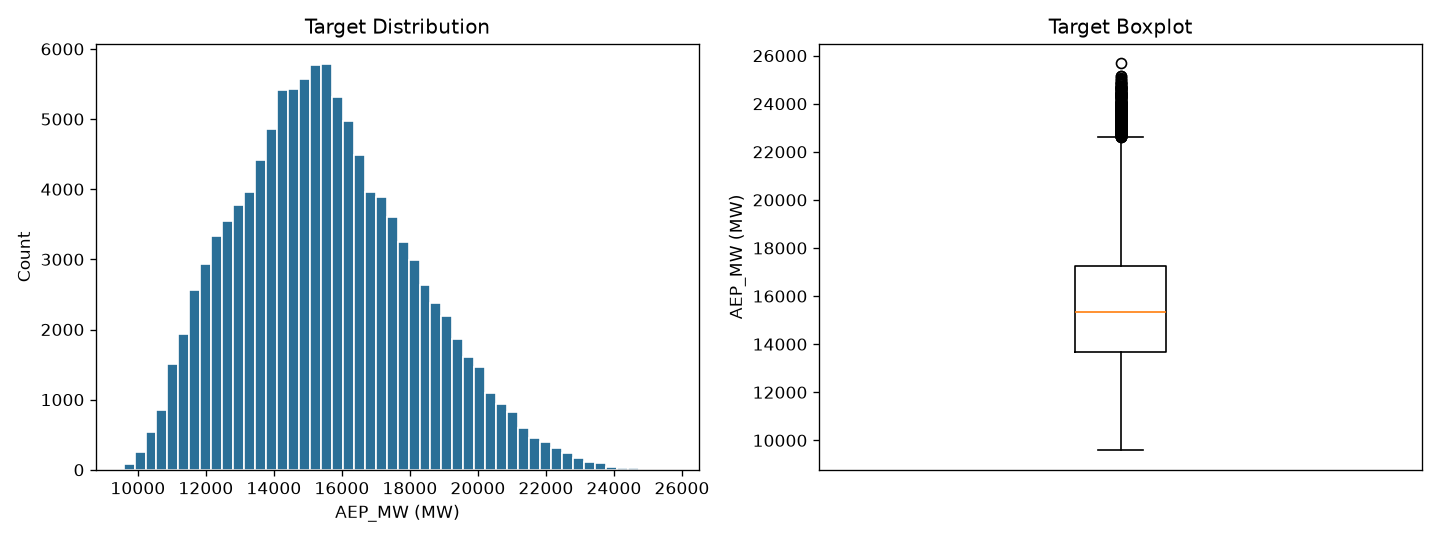

### Xu hướng development

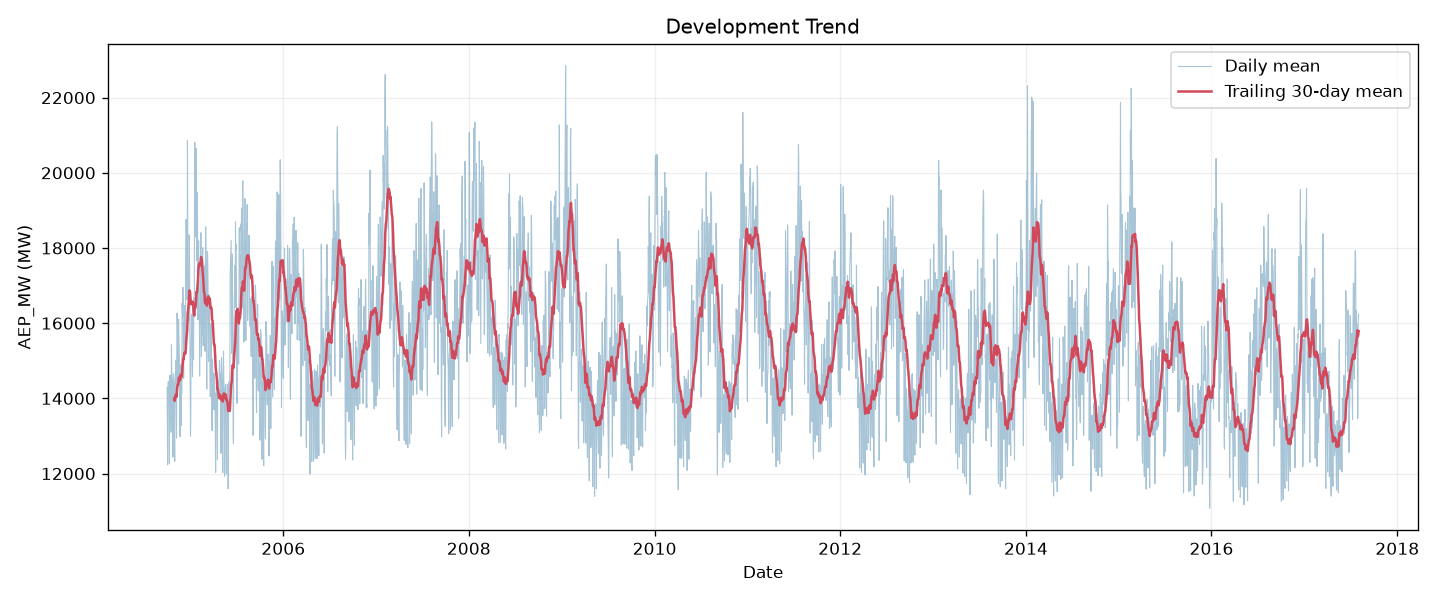

### Seasonality theo giờ, thứ và tháng

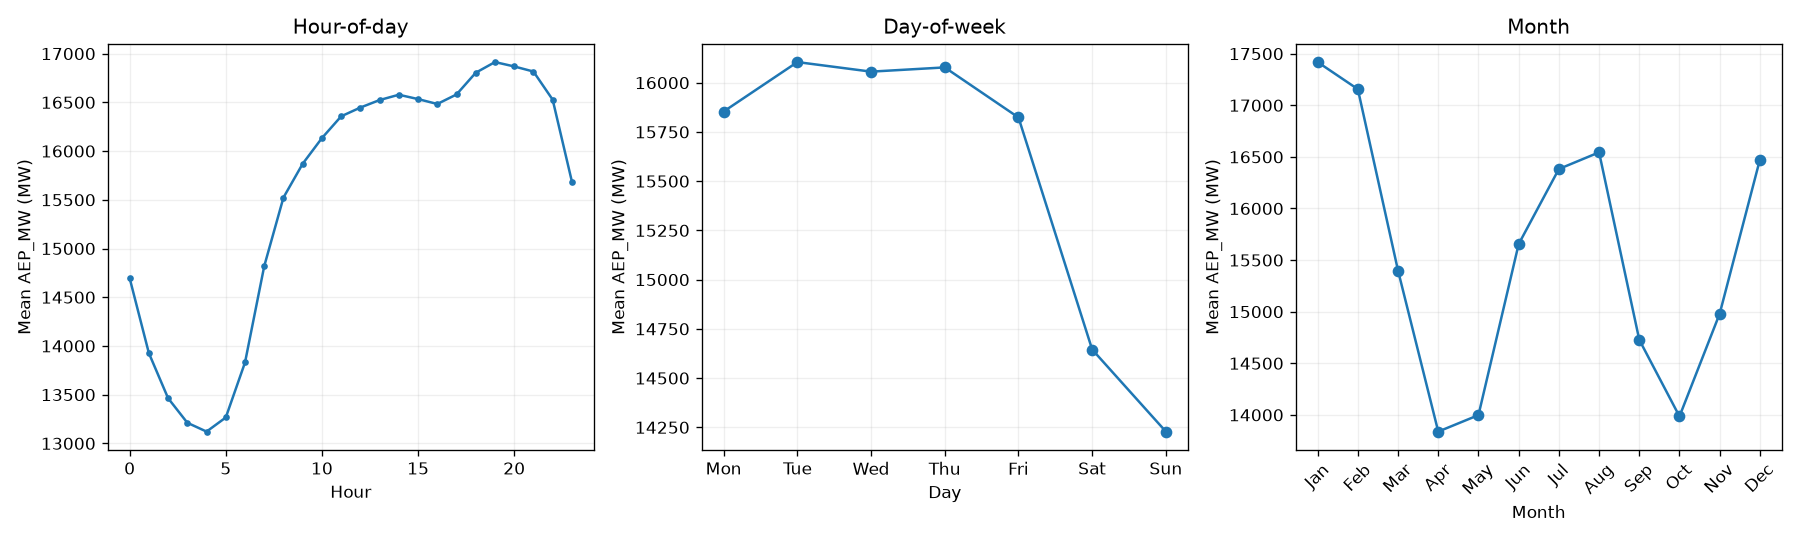

### Tương tác giữa giờ và thứ trong tuần

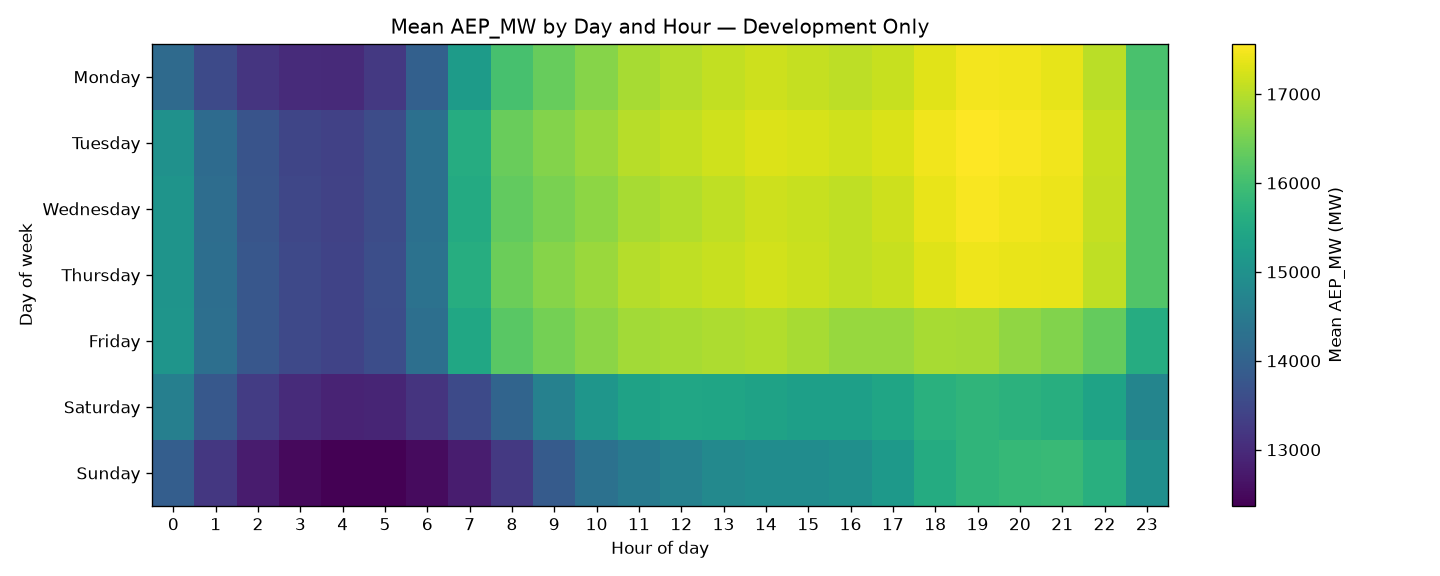

### Lag correlation 1–168 giờ

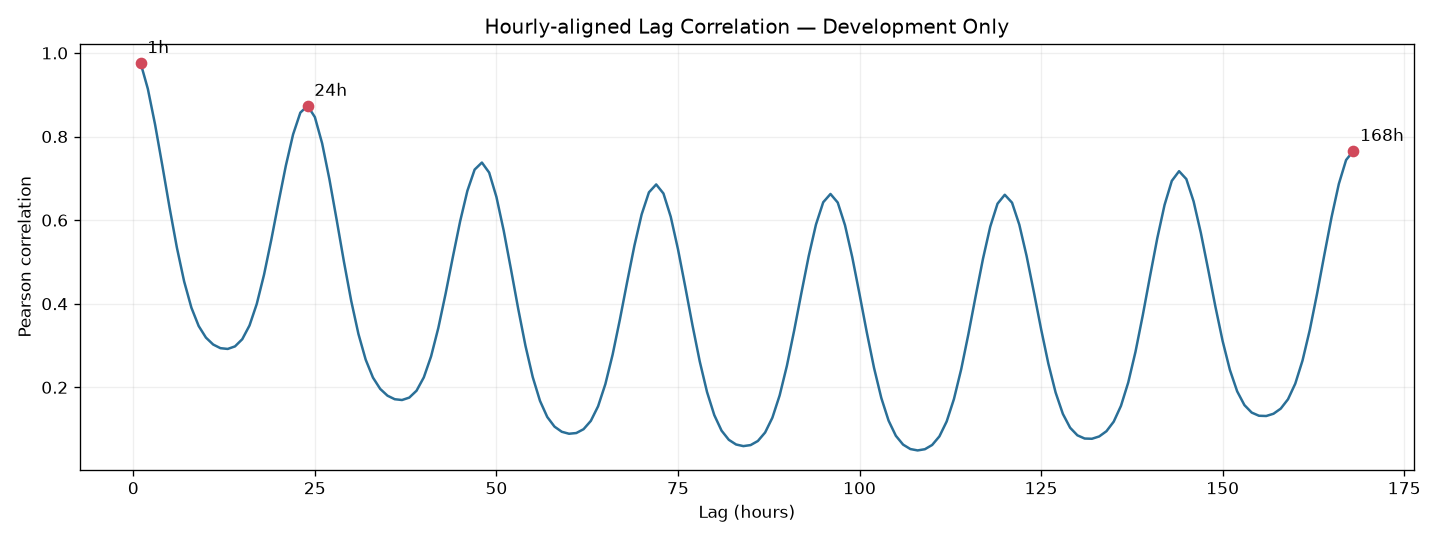

### Anomaly screening

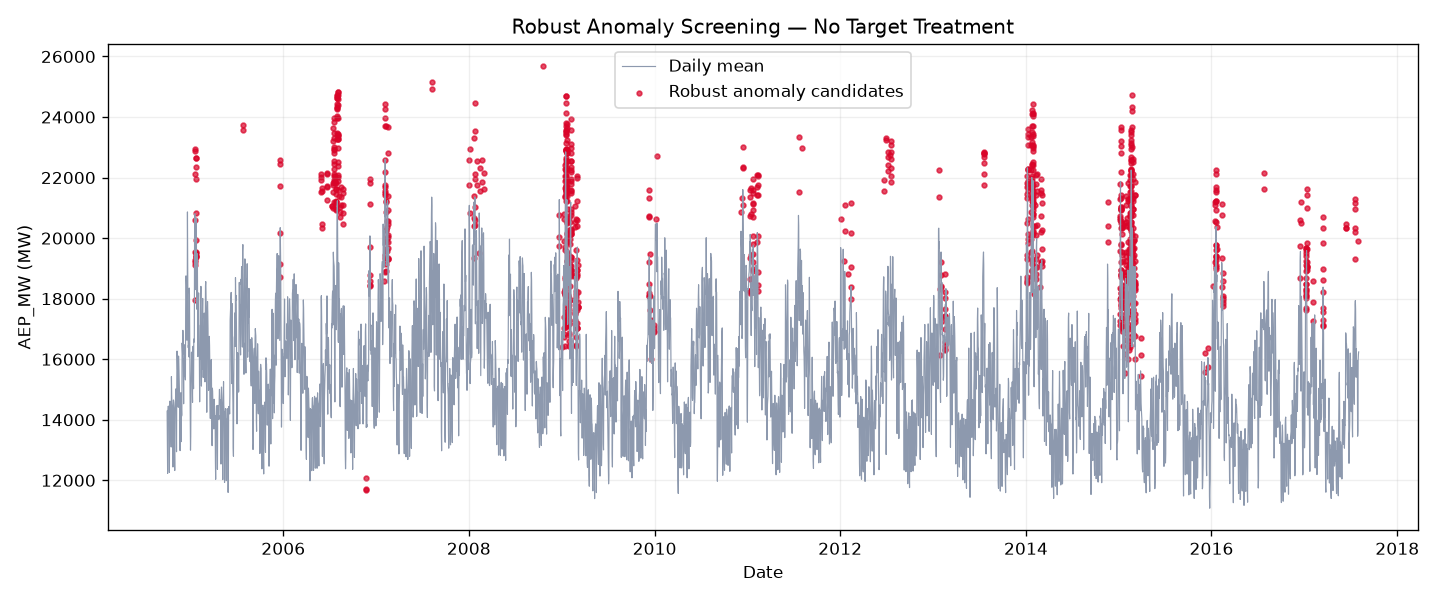

### Stability theo năm

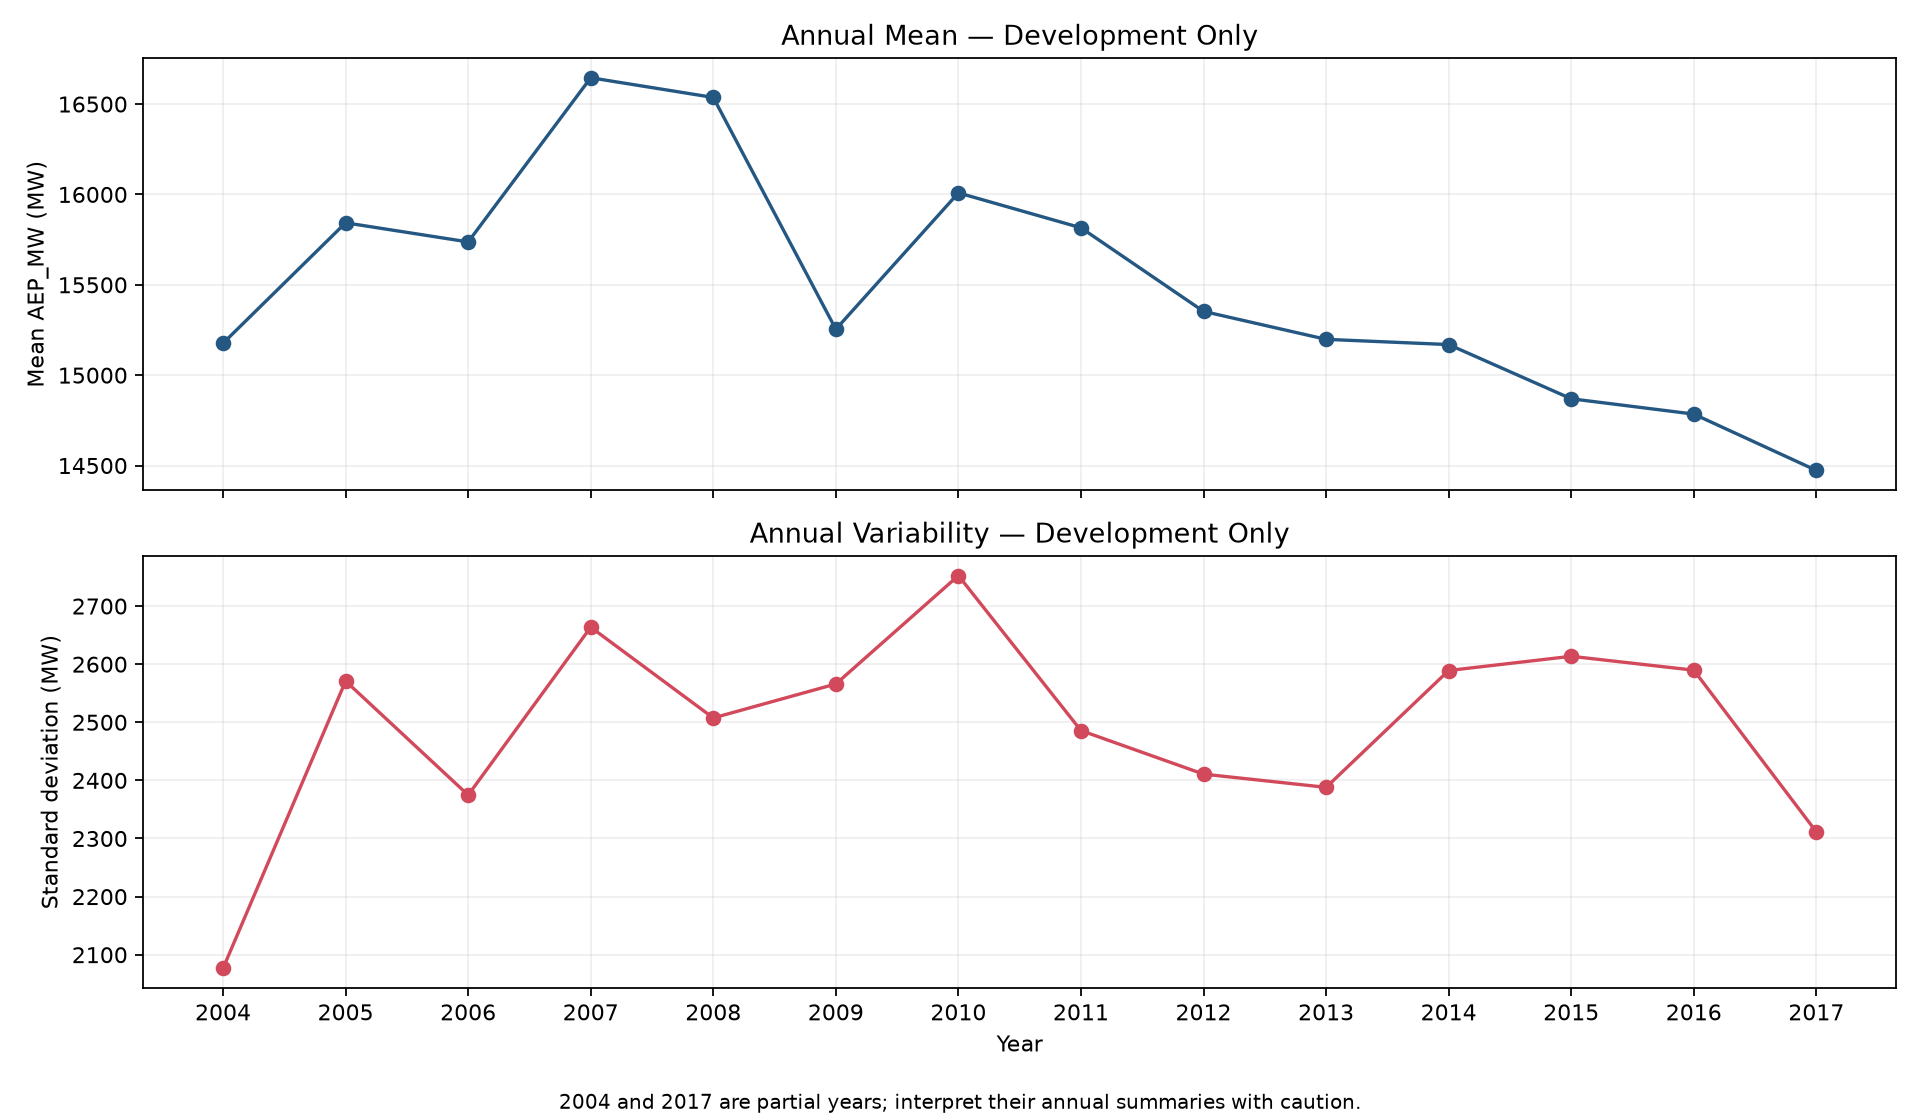

In [7]:
figure_titles = {
    "distribution": "Phân phối target",
    "trend": "Xu hướng development",
    "seasonality_profiles": "Seasonality theo giờ, thứ và tháng",
    "hour_day_heatmap": "Tương tác giữa giờ và thứ trong tuần",
    "lag_correlation": "Lag correlation 1–168 giờ",
    "anomaly_screening": "Anomaly screening",
}
figure_records = {record["name"]: record for record in phase_03_audit["figures"]}
for name, title in figure_titles.items():
    display(Markdown(f"### {title}"))
    display(DisplayImage(filename=str(project_root / figure_records[name]["path"])))
display(Markdown("### Stability theo năm"))
display(DisplayImage(filename=str(project_root / phase_03_presentation["figure"]["path"])))

**Kết luận:** Development có phụ thuộc ngắn hạn mạnh, chu kỳ ngày/tuần rõ và mức tiêu thụ thay đổi theo giờ, thứ, tháng và năm. Anomaly chỉ được screening, không tự động xóa. Các phát hiện được dùng làm evidence cho Feature Engineering; Historical Re-evaluation Holdout không được quan sát — **PASS**.

## Phase 4 — Feature Engineering

Biến lịch sử target và calendar thành 22 features time-safe cho one-step và recursive forecasting.

In [8]:
feature_groups = phase_04_audit["feature_groups"]
feature_dictionary = pd.DataFrame(
    [
        ["Lag", len(feature_groups["lags"]), ", ".join(feature_groups["lags"]), "Mức tiêu thụ tại các thời điểm quá khứ"],
        ["Shifted rolling", len(feature_groups["rolling"]), ", ".join(feature_groups["rolling"]), "Mức trung bình và variability gần đây"],
        ["Calendar", len(feature_groups["calendar"]), ", ".join(feature_groups["calendar"]), "Chu kỳ giờ, tuần, tháng đã biết trước"],
    ],
    columns=["Nhóm feature", "Số lượng", "Feature", "Ý nghĩa"],
)
display(style_table(feature_dictionary, caption="Feature dictionary — 22 features"))
feature_provenance = pd.DataFrame(
    [
        ["lag_1h, lag_2h, lag_3h", "EDA-driven", "Phụ thuộc ngắn hạn mạnh"],
        ["lag_23h, lag_24h, lag_25h", "EDA + design-driven", "Chu kỳ ngày; adjacent lags tăng độ bền cục bộ"],
        ["lag_48h", "Design-driven", "Ứng viên ghi nhớ hai ngày"],
        ["lag_168h", "EDA-driven", "Phụ thuộc theo tuần"],
        ["rolling 24h / 168h", "EDA + design-driven", "Level và variability theo ngày/tuần"],
        ["hour, day_of_week, month, is_weekend", "EDA + domain-driven", "Seasonality theo lịch đã quan sát"],
        ["cyclic sin/cos encodings", "Design-driven", "Giữ khoảng cách tuần hoàn của calendar"],
    ],
    columns=["Feature", "Nguồn quyết định", "Lý do"],
)
display(style_table(feature_provenance, caption="Feature provenance"))

Nhóm feature,Số lượng,Feature,Ý nghĩa
Lag,8,"lag_1h, lag_2h, lag_3h, lag_23h, lag_24h, lag_25h, lag_48h, lag_168h",Mức tiêu thụ tại các thời điểm quá khứ
Shifted rolling,4,"rolling_mean_24h, rolling_std_24h, rolling_mean_168h, rolling_std_168h",Mức trung bình và variability gần đây
Calendar,10,"hour, day_of_week, month, is_weekend, hour_sin, hour_cos, day_of_week_sin, day_of_week_cos, month_sin, month_cos","Chu kỳ giờ, tuần, tháng đã biết trước"


Feature,Nguồn quyết định,Lý do
"lag_1h, lag_2h, lag_3h",EDA-driven,Phụ thuộc ngắn hạn mạnh
"lag_23h, lag_24h, lag_25h",EDA + design-driven,Chu kỳ ngày; adjacent lags tăng độ bền cục bộ
lag_48h,Design-driven,Ứng viên ghi nhớ hai ngày
lag_168h,EDA-driven,Phụ thuộc theo tuần
rolling 24h / 168h,EDA + design-driven,Level và variability theo ngày/tuần
"hour, day_of_week, month, is_weekend",EDA + domain-driven,Seasonality theo lịch đã quan sát
cyclic sin/cos encodings,Design-driven,Giữ khoảng cách tuần hoàn của calendar


Feature,Null count,Nguyên nhân
8 lag features,194,Lớn nhất tại lag_168h; history chưa khả dụng
Rolling 24h,648,Window phải đủ 24 observations sau shift(1)
Rolling 168h,"4,427",Window phải đủ 168 observations sau shift(1)
10 calendar features,0,Tính trực tiếp từ target timestamp


**Availability:** 108,108/112,535 rows có đủ 22 features; bắt đầu từ `2004-10-08 01:00:00`. Phase 4 không impute và không xóa row.

**Leakage control — PASS:** rolling dùng `shift(1)`, không centered rolling, không current/future target và không dùng Historical Re-evaluation Holdout.

**Forecast compatibility:** one-step dùng actual history đến `T-1`; recursive 24-hour dùng actual history đến origin và các prediction đã sinh.

### Correlation của target, lag và rolling features

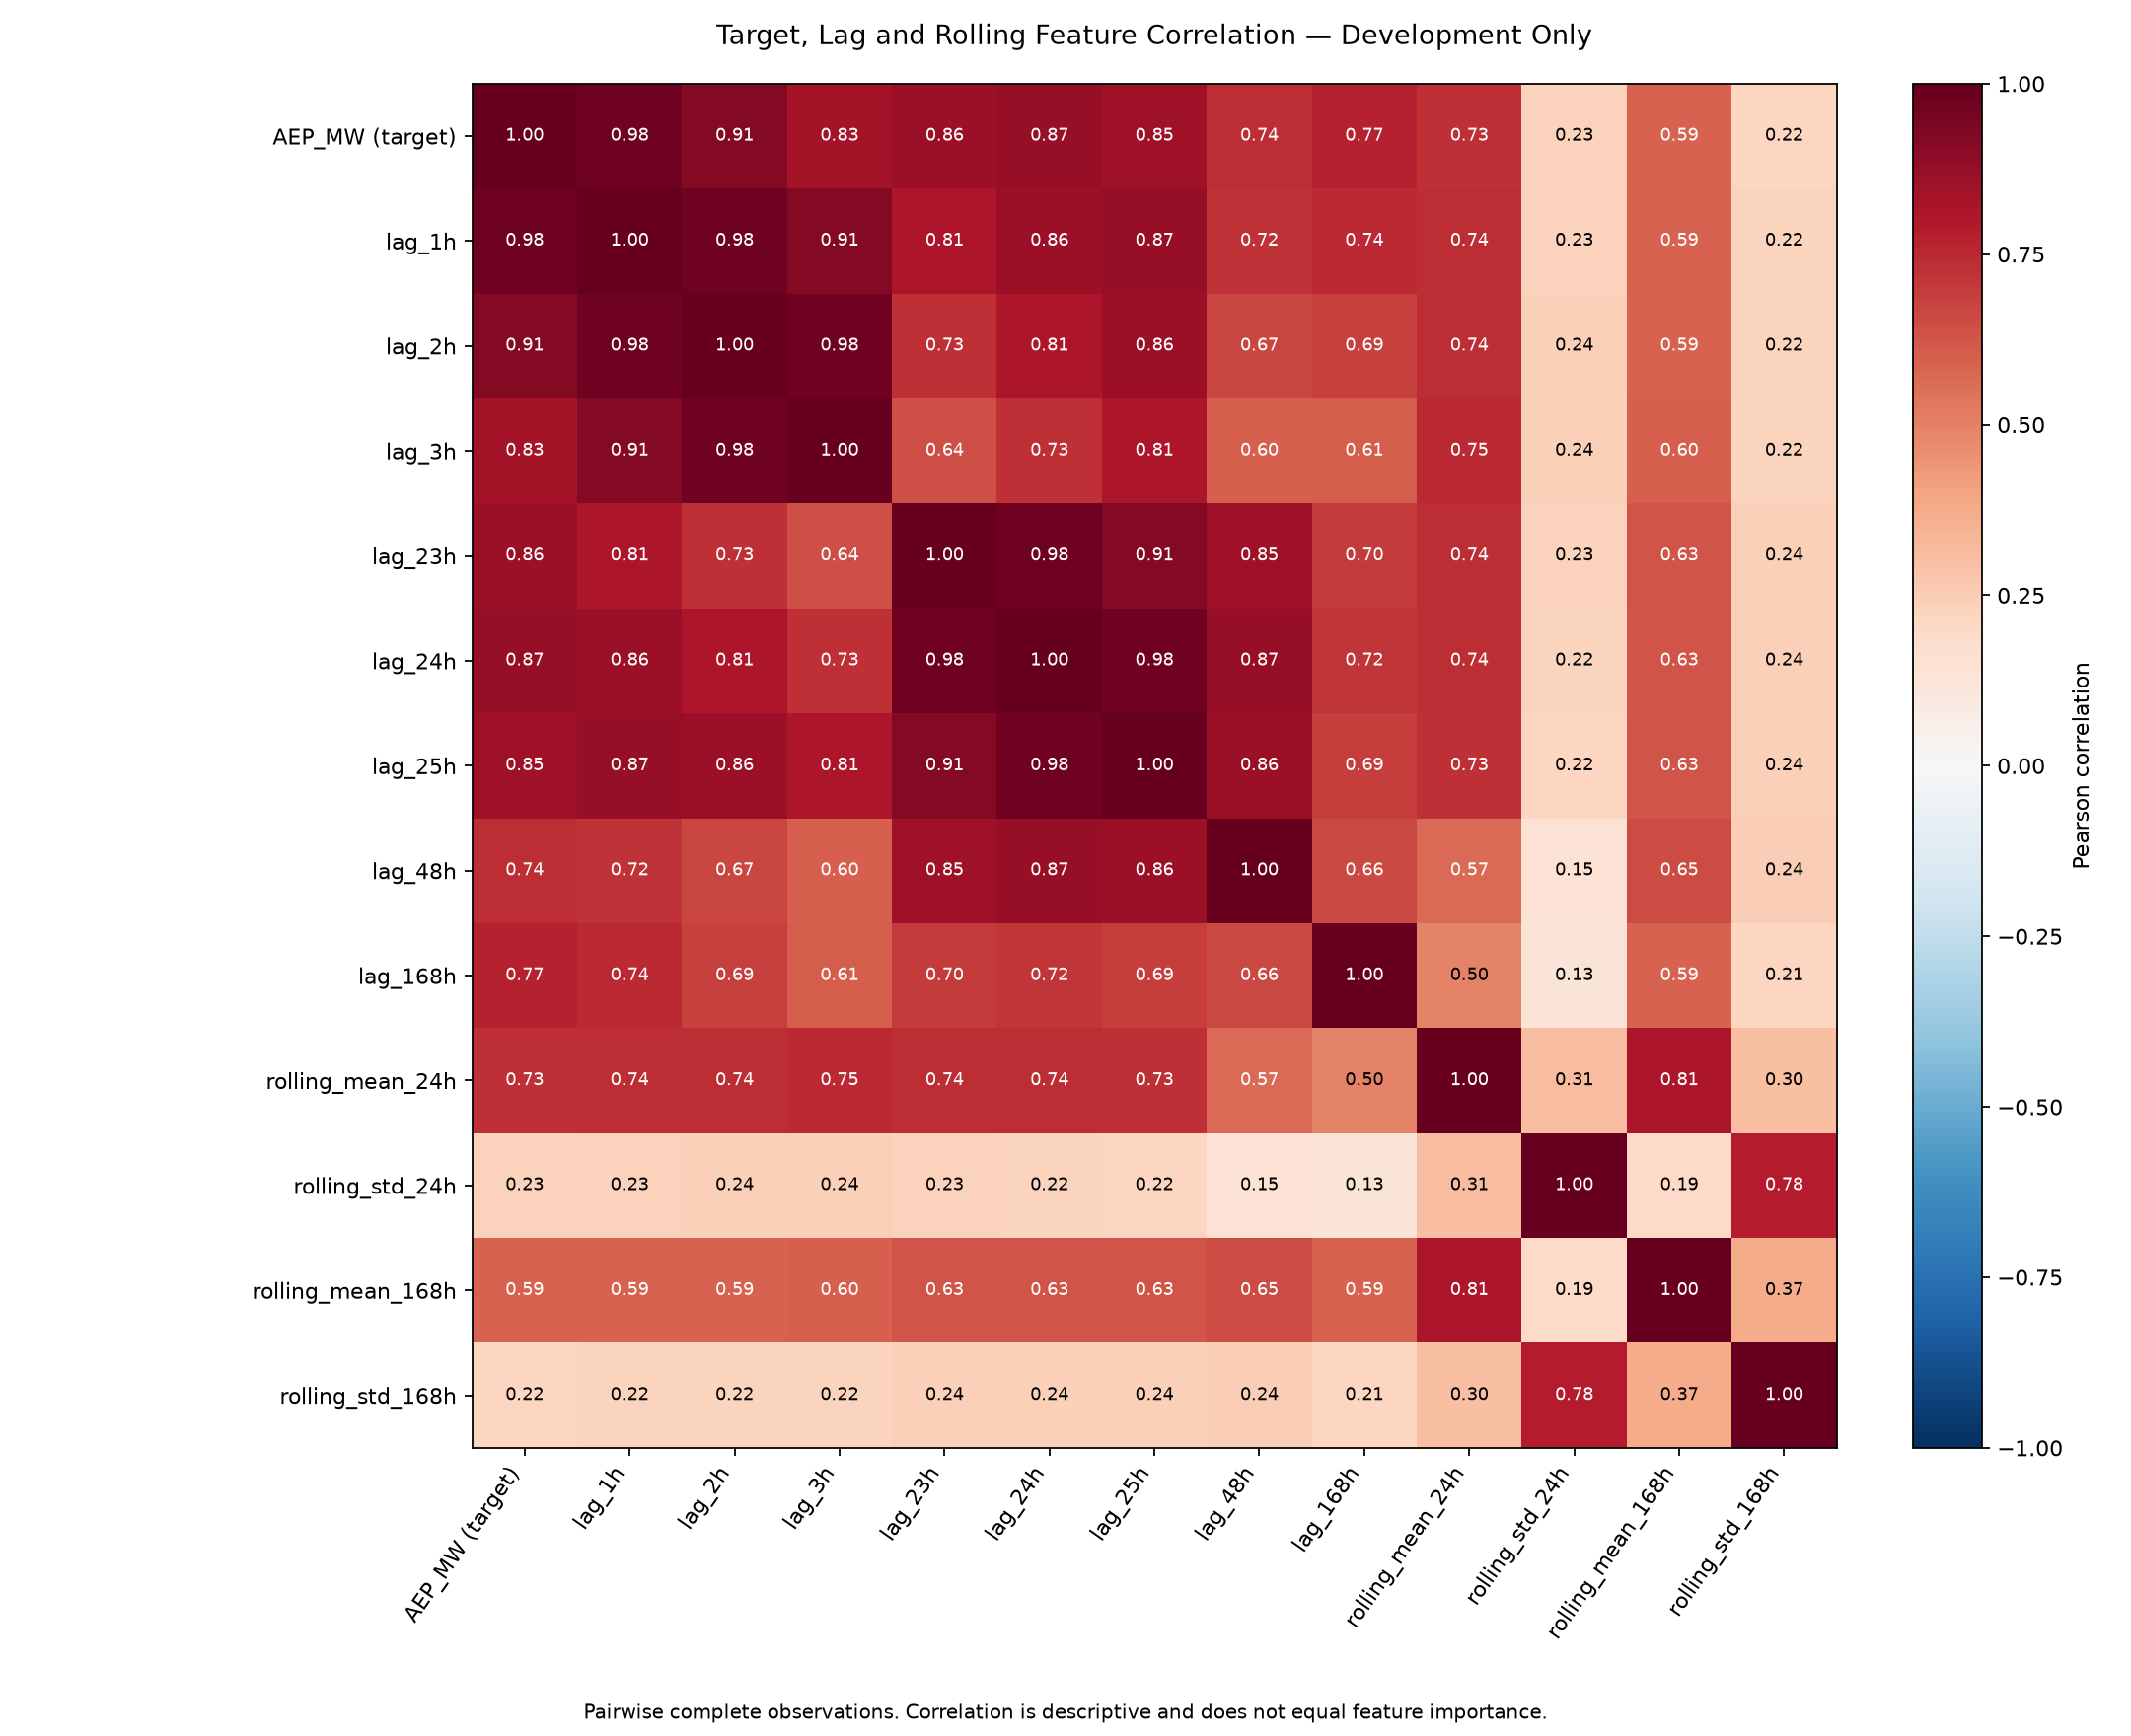

Heatmap dùng pairwise Pearson trên Development. Correlation mô tả quan hệ tuyến tính, không phải quan hệ nhân quả hay feature importance của XGBoost.

In [9]:
null_counts = phase_04_audit["null_counts"]
availability_rows = [
    ["8 lag features", max(null_counts[name] for name in feature_groups["lags"]), "Lớn nhất tại lag_168h; history chưa khả dụng"],
    ["Rolling 24h", null_counts["rolling_mean_24h"], "Window phải đủ 24 observations sau shift(1)"],
    ["Rolling 168h", null_counts["rolling_mean_168h"], "Window phải đủ 168 observations sau shift(1)"],
    ["10 calendar features", 0, "Tính trực tiếp từ target timestamp"],
]
availability_summary = pd.DataFrame(
    availability_rows, columns=["Feature", "Null count", "Nguyên nhân"]
)
display(style_table(availability_summary, formats={"Null count": "{:,}"}, caption="Feature availability"))

checks = phase_04_audit["checks"]
display(Markdown(
    f"**Availability:** {phase_04_audit['rows_with_all_features']:,}/{phase_04_audit['development']['rows']:,} rows có đủ 22 features; "
    f"bắt đầu từ `{phase_04_audit['first_fully_available_timestamp']}`. Phase 4 không impute và không xóa row."
))
display(Markdown(
    "**Leakage control — PASS:** rolling dùng `shift(1)`, không centered rolling, không current/future target và không dùng Historical Re-evaluation Holdout."
))
display(Markdown(
    "**Forecast compatibility:** one-step dùng actual history đến `T-1`; recursive 24-hour dùng actual history đến origin và các prediction đã sinh."
))
display(Markdown("### Correlation của target, lag và rolling features"))
display(DisplayImage(filename=str(project_root / phase_04_presentation["figure"]["path"])))
display(Markdown(
    "Heatmap dùng pairwise Pearson trên Development. Correlation mô tả quan hệ tuyến tính, không phải quan hệ nhân quả hay feature importance của XGBoost."
))

**Kết luận:** 22 features gồm lag, shifted rolling và calendar đều dùng thông tin khả dụng tại forecast origin; không impute, không xóa row và không dùng Historical Re-evaluation Holdout — **PASS**.

**Limitation:** EDA cho thấy level thay đổi theo năm nhưng core feature set không dùng `year` hoặc trend feature. Lag và rolling phản ánh level gần nhất; khả năng xử lý long-term drift cần được đánh giá qua expanding-window validation và Historical Re-evaluation Holdout.

## Phase 5 — Time Series to Supervised Learning

Với forecast origin `t` và target timestamp `T = t + 1 giờ`: lịch sử đến `t` tạo `X(T)`, còn `AEP_MW` tại `T` là `y(T)`.

### Quy trình chuyển đổi

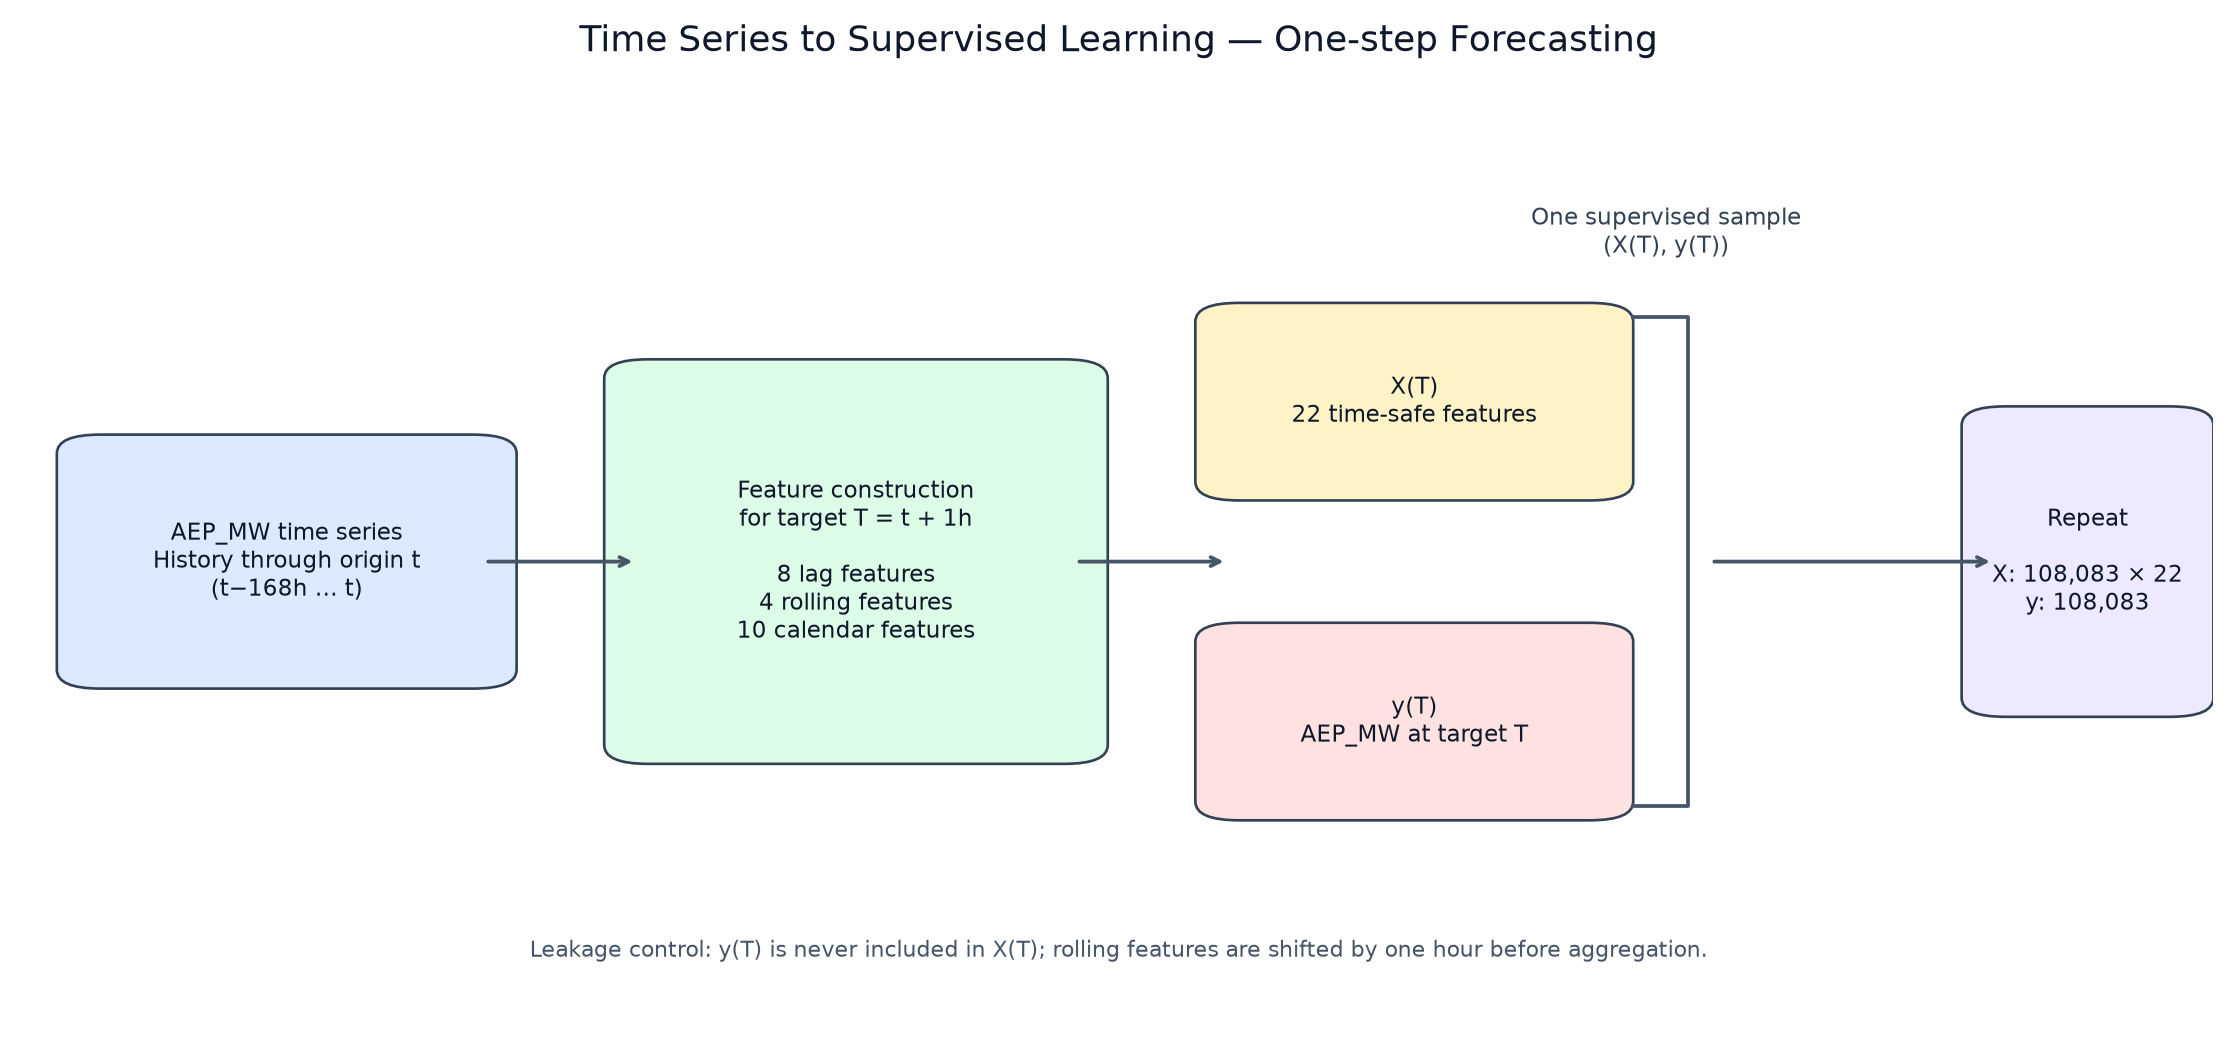

Thành phần sample,Giá trị,Ý nghĩa
Forecast origin t,2004-10-08 00:00:00,Thông tin mới nhất model được phép sử dụng
Target timestamp T,2004-10-08 01:00:00,Thời điểm cần dự báo
lag_1h,"13,271.000",AEP_MW tại T−1h
lag_24h,"12,484.000",AEP_MW tại T−24h
lag_168h,"12,379.000",AEP_MW tại T−168h
rolling_mean_24h,"14,450.333",Trung bình T−24h đến T−1h
Calendar,"hour=1, day_of_week=4, month=10",Biết trước tại target timestamp
Target y(T),"12,468.000",AEP_MW tại T; không nằm trong X(T)


Supervised dataset,Kết quả
Development timestamps,"112,535"
Eligible supervised samples,"108,083"
X shape,"108,083 × 22"
y shape,"108,083"
Invalid feature vector,"4,427"
Missing target with valid X,25
Imputation,none
Shuffle,False


In [10]:
display(Markdown("### Quy trình chuyển đổi"))
display(DisplayImage(filename=str(phase_05_conversion_figure_path)))
sample = phase_05_presentation["example_sample"]
sample_features = sample["feature_values"]
sample_summary = pd.DataFrame(
    [
        ["Forecast origin t", sample["forecast_origin"], "Thông tin mới nhất model được phép sử dụng"],
        ["Target timestamp T", sample["target_timestamp"], "Thời điểm cần dự báo"],
        ["lag_1h", sample_features["lag_1h"], "AEP_MW tại T−1h"],
        ["lag_24h", sample_features["lag_24h"], "AEP_MW tại T−24h"],
        ["lag_168h", sample_features["lag_168h"], "AEP_MW tại T−168h"],
        ["rolling_mean_24h", sample_features["rolling_mean_24h"], "Trung bình T−24h đến T−1h"],
        ["Calendar", f"hour={int(sample_features['hour'])}, day_of_week={int(sample_features['day_of_week'])}, month={int(sample_features['month'])}", "Biết trước tại target timestamp"],
        ["Target y(T)", sample["target_value"], "AEP_MW tại T; không nằm trong X(T)"],
    ],
    columns=["Thành phần sample", "Giá trị", "Ý nghĩa"],
)
display(style_table(sample_summary, formats={"Giá trị": lambda value: f"{value:,.3f}" if isinstance(value, float) else value}, caption="Một supervised sample thực tế"))
matrix_summary = phase_05_presentation["matrix_summary"]
xy_summary = pd.DataFrame(
    [
        ["Development timestamps", matrix_summary["candidate_rows"]],
        ["Eligible supervised samples", matrix_summary["eligible_samples"]],
        ["X shape", f"{matrix_summary['x_shape'][0]:,} × {matrix_summary['x_shape'][1]}"],
        ["y shape", f"{matrix_summary['y_shape'][0]:,}"],
        ["Invalid feature vector", matrix_summary["invalid_feature_vector"]],
        ["Missing target with valid X", matrix_summary["missing_target_with_valid_features"]],
        ["Imputation", matrix_summary["imputation"]],
        ["Shuffle", matrix_summary["shuffle"]],
    ],
    columns=["Supervised dataset", "Kết quả"],
)
display(style_table(xy_summary, formats={"Kết quả": lambda value: f"{value:,}" if isinstance(value, int) and not isinstance(value, bool) else value}, caption="Kết quả chuyển đổi toàn bộ Development"))

In [11]:
fold_summary = pd.DataFrame(
    [
        [
            fold["fold"],
            fold["train"]["raw_rows"],
            fold["train"]["eligible_rows"],
            fold["validation"]["raw_rows"],
            fold["validation"]["eligible_rows"],
            fold["shuffle"],
        ]
        for fold in phase_05_audit["cross_validation"]["folds"]
    ],
    columns=["Fold", "Train raw", "Train eligible", "Validation raw", "Validation eligible", "Shuffle"],
)
display(style_table(
    fold_summary,
    formats={column: "{:,}" for column in ["Train raw", "Train eligible", "Validation raw", "Validation eligible"]},
    caption="Expanding-window folds",
))

Fold,Train raw,Train eligible,Validation raw,Validation eligible,Shuffle
1,"68,711","65,670","8,760","8,253",False
2,"77,471","73,923","8,760","8,363",False
3,"86,231","82,286","8,760","8,591",False
4,"94,991","90,877","8,784","8,615",False
5,"103,775","99,492","8,760","8,591",False


**Kết quả:** 108.083 eligible samples với cùng population cho mọi candidate — **PASS**.

## Phase 6 — Model Training and Selection

Model selection chỉ dựa trên one-step development temporal CV.

In [12]:
linear_aggregate = phase_06_supplemental_linear["aggregate"]
phase_06_rows = []
for candidate in phase_06_cv["candidate_results"]:
    aggregate = candidate["aggregate"]
    phase_06_rows.append(
        [
            candidate["candidate"],
            aggregate["mean_cv_mae"],
            aggregate["mean_cv_rmse"],
            aggregate["cv_mae_standard_deviation"],
            aggregate["validation_samples"],
            "Official model selection",
            candidate["candidate"] == phase_06_cv["selected_candidate"],
        ]
    )
phase_06_rows.append([
    "linear_regression",
    linear_aggregate["mean_cv_mae"],
    linear_aggregate["mean_cv_rmse"],
    linear_aggregate["cv_mae_standard_deviation"],
    linear_aggregate["validation_samples"],
    "Post-hoc supplemental",
    False,
])
phase_06_comparison = pd.DataFrame(
    phase_06_rows,
    columns=["Candidate", "Mean CV MAE (MW)", "Mean CV RMSE (MW)", "MAE std (MW)", "Validation samples", "Evidence scope", "Selected"],
)
def highlight_selected_candidate(row):
    style = SELECTED_ROW_STYLE
    return [style if row["Selected"] else "" for _ in row]
display(
    style_table(
        phase_06_comparison,
        formats={"Mean CV MAE (MW)": "{:,.3f}", "Mean CV RMSE (MW)": "{:,.3f}", "MAE std (MW)": "{:,.3f}", "Validation samples": "{:,}"},
        row_highlighter=highlight_selected_candidate,
        caption="So sánh model trên Development CV",
    )
)

Candidate,Mean CV MAE (MW),Mean CV RMSE (MW),MAE std (MW),Validation samples,Evidence scope,Selected
persistence,416.456,538.293,3.040,"42,413",Official model selection,False
seasonal_naive_24,958.058,"1,290.709",51.809,"42,413",Official model selection,False
xgboost_baseline,118.614,156.643,3.185,"42,413",Official model selection,False
random_forest,125.403,169.882,4.433,"42,413",Official model selection,False
xgboost_tuned,108.254,143.850,3.144,"42,413",Official model selection,True
linear_regression,136.762,186.096,4.701,"42,413",Post-hoc supplemental,False


Training / Model lock,Kết quả
Tuning design,24 candidates × 5 folds = 120 fits
Selected candidate,xgboost_tuned
Selected tuning index,22
Mean CV MAE,108.254
Mean CV RMSE,143.850
Holdout evaluated,False


Locked parameter,Giá trị
n_estimators,500.000000
max_depth,7.000000
learning_rate,0.100000
subsample,0.700000
colsample_bytree,0.700000
reg_alpha,1.000000
reg_lambda,10.000000


### Development CV comparison

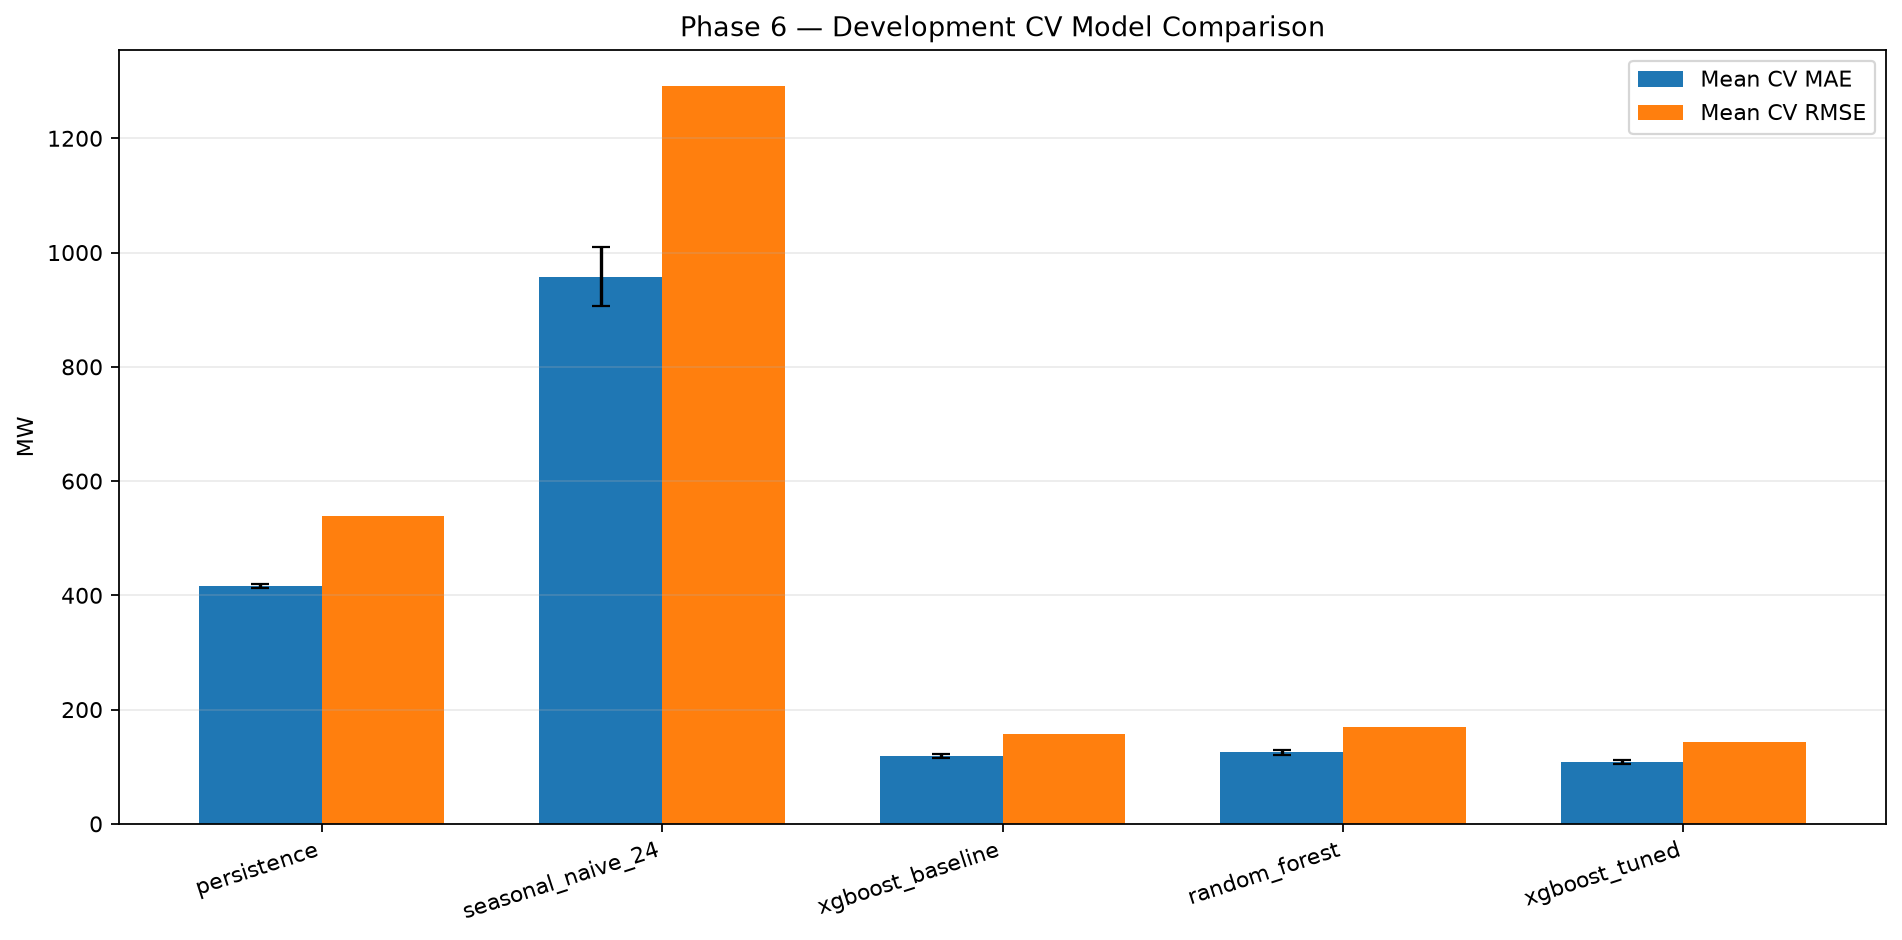

### XGBoost tuning: 24 candidates

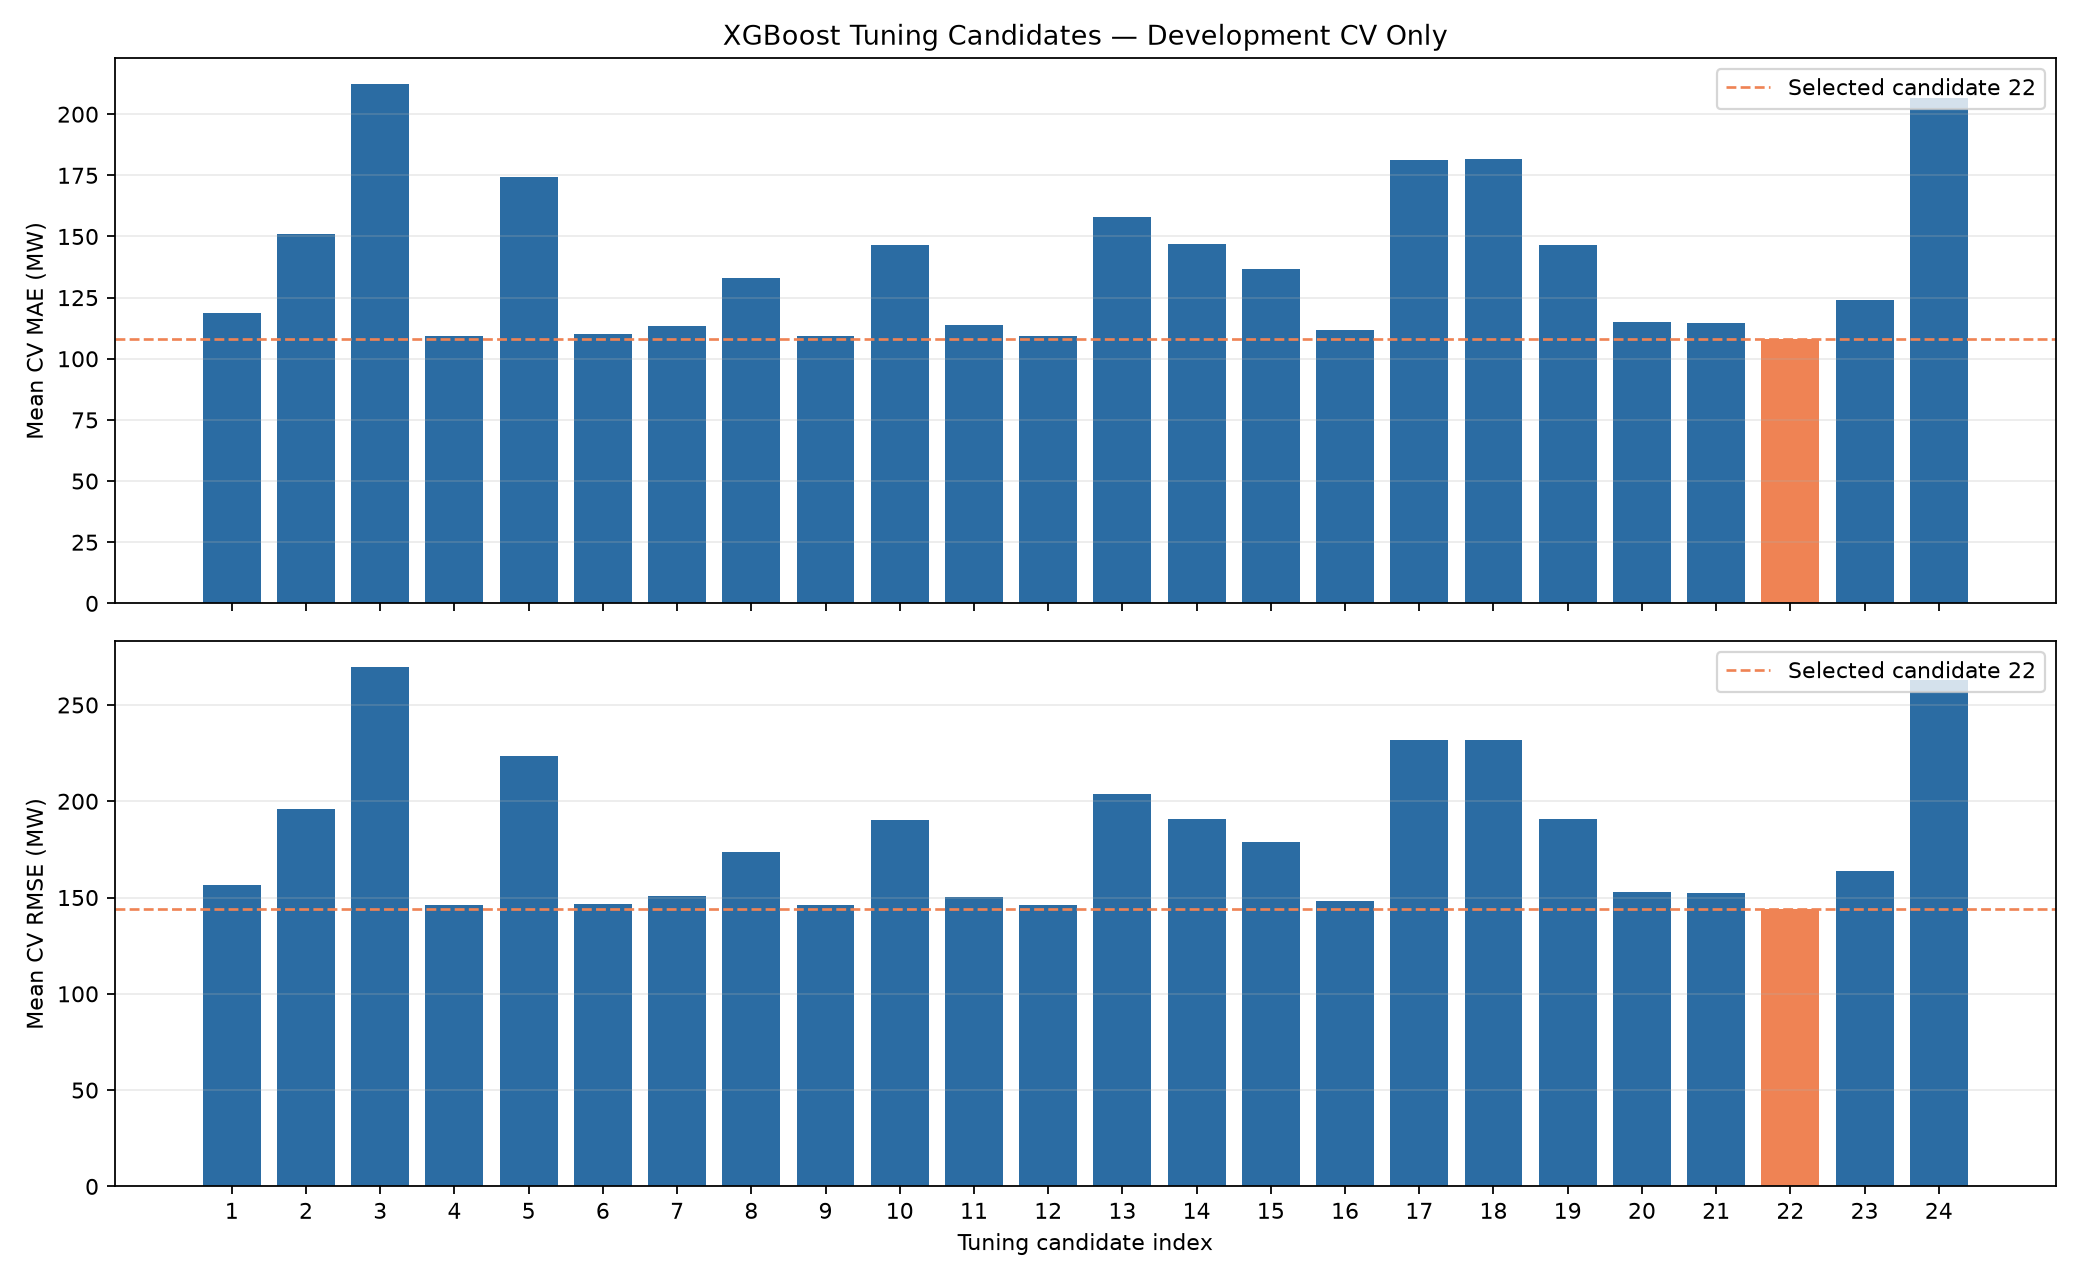

### Candidate được chọn qua 5 temporal folds

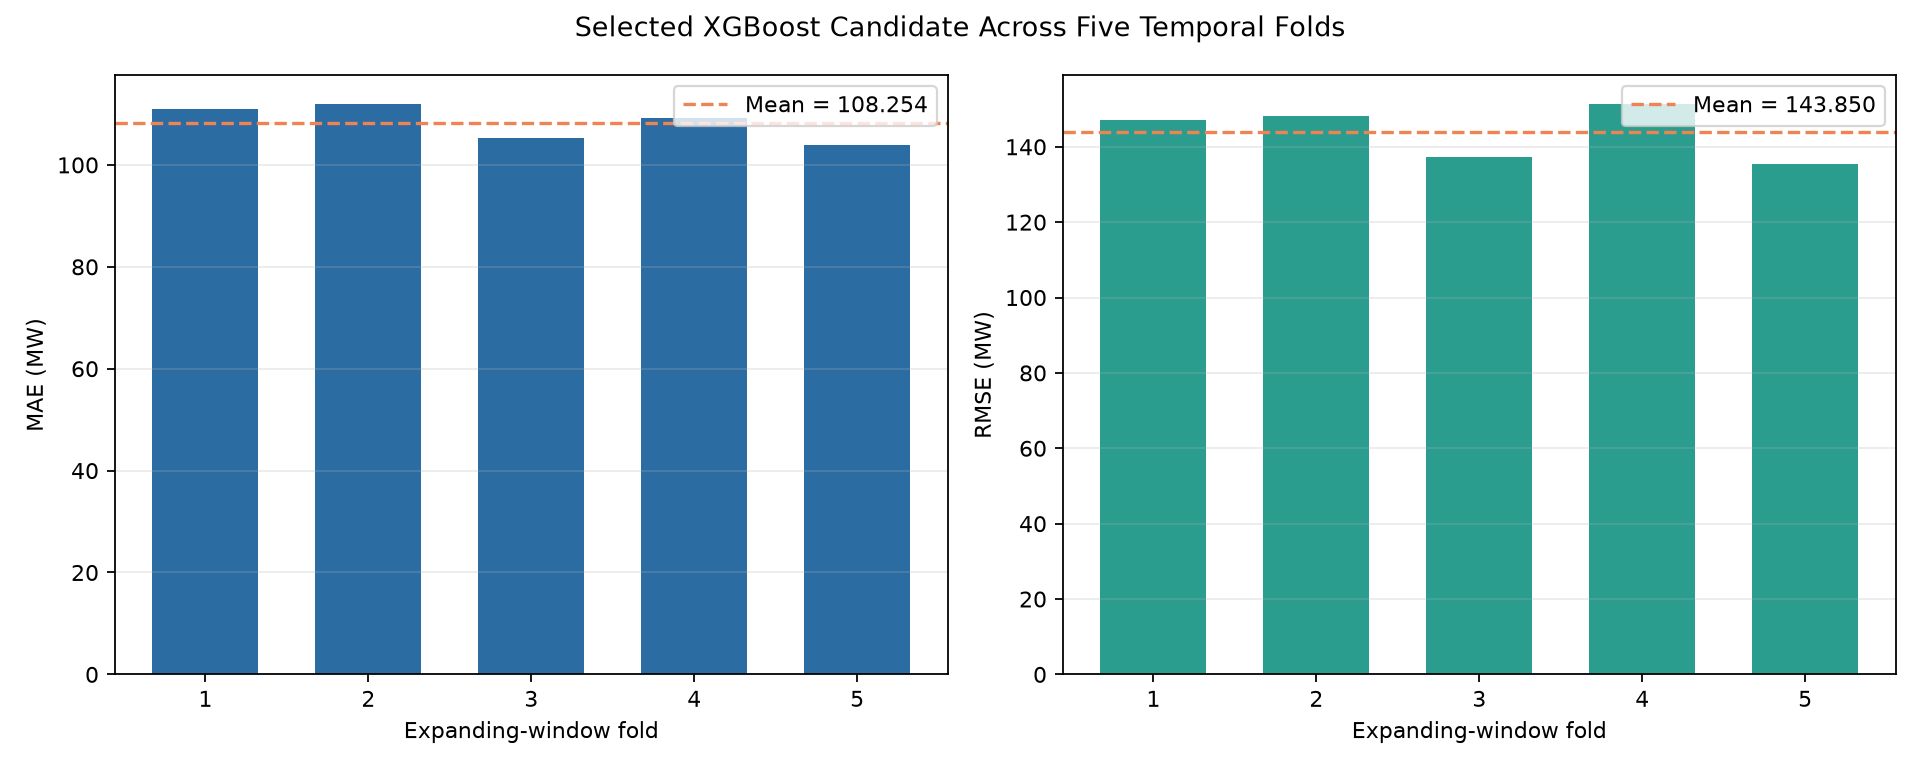

In [13]:
training_summary = phase_06_training_diagnostics["training_summary"]
selected_diagnostics = phase_06_training_diagnostics["selected_candidate"]
lock_summary = pd.DataFrame(
    [
        ["Tuning design", f"{training_summary['tuning_candidates']} candidates × {training_summary['folds_per_candidate']} folds = {training_summary['completed_tuning_fits']} fits"],
        ["Selected candidate", phase_06_lock["selected_candidate"]],
        ["Selected tuning index", selected_diagnostics["tuning_candidate_index"]],
        ["Mean CV MAE", phase_06_lock["selection_evidence"]["mean_cv_mae"]],
        ["Mean CV RMSE", phase_06_lock["selection_evidence"]["mean_cv_rmse"]],
        ["Holdout evaluated", phase_06_lock["holdout_evaluated"]],
    ],
    columns=["Training / Model lock", "Kết quả"],
)
display(style_table(lock_summary, formats={"Kết quả": lambda value: f"{value:,.3f}" if isinstance(value, float) else value}, caption="Model lock"))
locked_parameter_names = ["n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree", "reg_alpha", "reg_lambda"]
locked_parameters = pd.DataFrame(
    [[name, phase_06_lock["locked_parameters"][name]] for name in locked_parameter_names],
    columns=["Locked parameter", "Giá trị"],
)
display(style_table(locked_parameters, caption="Locked parameters"))
display(Markdown("### Development CV comparison"))
display(DisplayImage(filename=str(phase_06_figure_path)))
display(Markdown("### XGBoost tuning: 24 candidates"))
display(DisplayImage(filename=str(phase_06_tuning_figure_path)))
display(Markdown("### Candidate được chọn qua 5 temporal folds"))
display(DisplayImage(filename=str(phase_06_fold_figure_path)))

**Kết quả:** `xgboost_tuned` được khóa với CV MAE 108,254 MW — **PASS**.

### Supplemental — Linear Regression and Lag Sensitivity

Hai thí nghiệm development-only để trả lời câu hỏi mở rộng của đề.

In [14]:
xgboost_aggregate = phase_06_supplemental_linear["official_xgboost_reference"]["aggregate"]
improvement_percent = 100 * (linear_aggregate["mean_cv_mae"] - xgboost_aggregate["mean_cv_mae"]) / linear_aggregate["mean_cv_mae"]
display(Markdown(
    f"**XGBoost vs Linear Regression:** tuned XGBoost giảm CV MAE **{improvement_percent:.3f}%** "
    f"trên cùng **{linear_aggregate['validation_samples']:,} validation samples**. "
    "Linear Regression là post-hoc supplemental evidence và không thay đổi model lock."
))

**XGBoost vs Linear Regression:** tuned XGBoost giảm CV MAE **20.845%** trên cùng **42,413 validation samples**. Linear Regression là post-hoc supplemental evidence và không thay đổi model lock.

In [15]:
lag_sensitivity_table = pd.DataFrame(
    [
        [result["p"], result["natural_eligible_samples"], result["aggregate"]["validation_samples"], result["aggregate"]["mean_cv_mae"], result["aggregate"]["mean_cv_rmse"]]
        for result in phase_06_supplemental_lag["p_results"]
    ],
    columns=["Lag p", "Natural eligible", "Common validation samples", "Mean CV MAE (MW)", "Mean CV RMSE (MW)"],
)
best_observed_p = int(lag_sensitivity_table.loc[lag_sensitivity_table["Mean CV MAE (MW)"].idxmin(), "Lag p"])
def highlight_best_observed_lag(row):
    return [SELECTED_ROW_STYLE if row["Lag p"] == best_observed_p else "" for _ in row]
display(style_table(
    lag_sensitivity_table,
    formats={"Natural eligible": "{:,}", "Common validation samples": "{:,}", "Mean CV MAE (MW)": "{:,.3f}", "Mean CV RMSE (MW)": "{:,.3f}"},
    row_highlighter=highlight_best_observed_lag,
    caption="Lag-p sensitivity",
))
display(Markdown("Mọi giá trị `p` dùng exact common train/validation timestamps hợp lệ cho `p=168`; vì vậy metric được so sánh trên cùng population."))

Lag p,Natural eligible,Common validation samples,Mean CV MAE (MW),Mean CV RMSE (MW)
1,"112,482","42,413",418.024,537.415
6,"112,347","42,413",181.480,253.183
12,"112,185","42,413",164.377,228.723
24,"111,861","42,413",135.706,185.067
48,"111,213","42,413",132.157,177.091
168,"108,083","42,413",135.620,180.438


Mọi giá trị `p` dùng exact common train/validation timestamps hợp lệ cho `p=168`; vì vậy metric được so sánh trên cùng population.

#### Linear Regression và official XGBoost reference

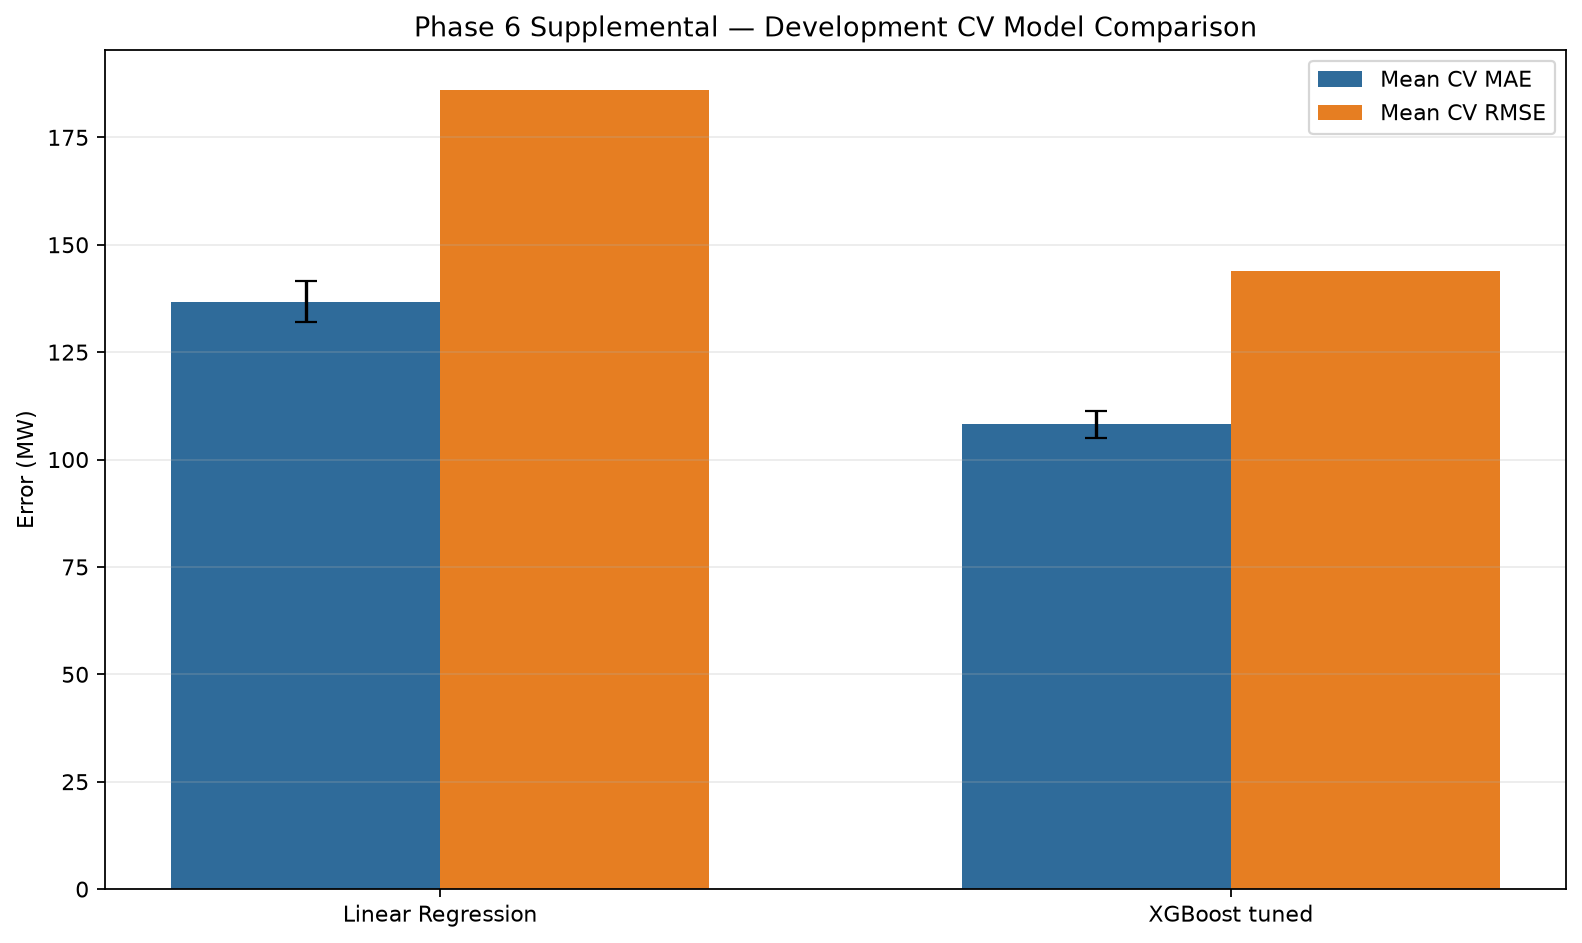

#### Sensitivity khi tăng số lag liên tiếp p

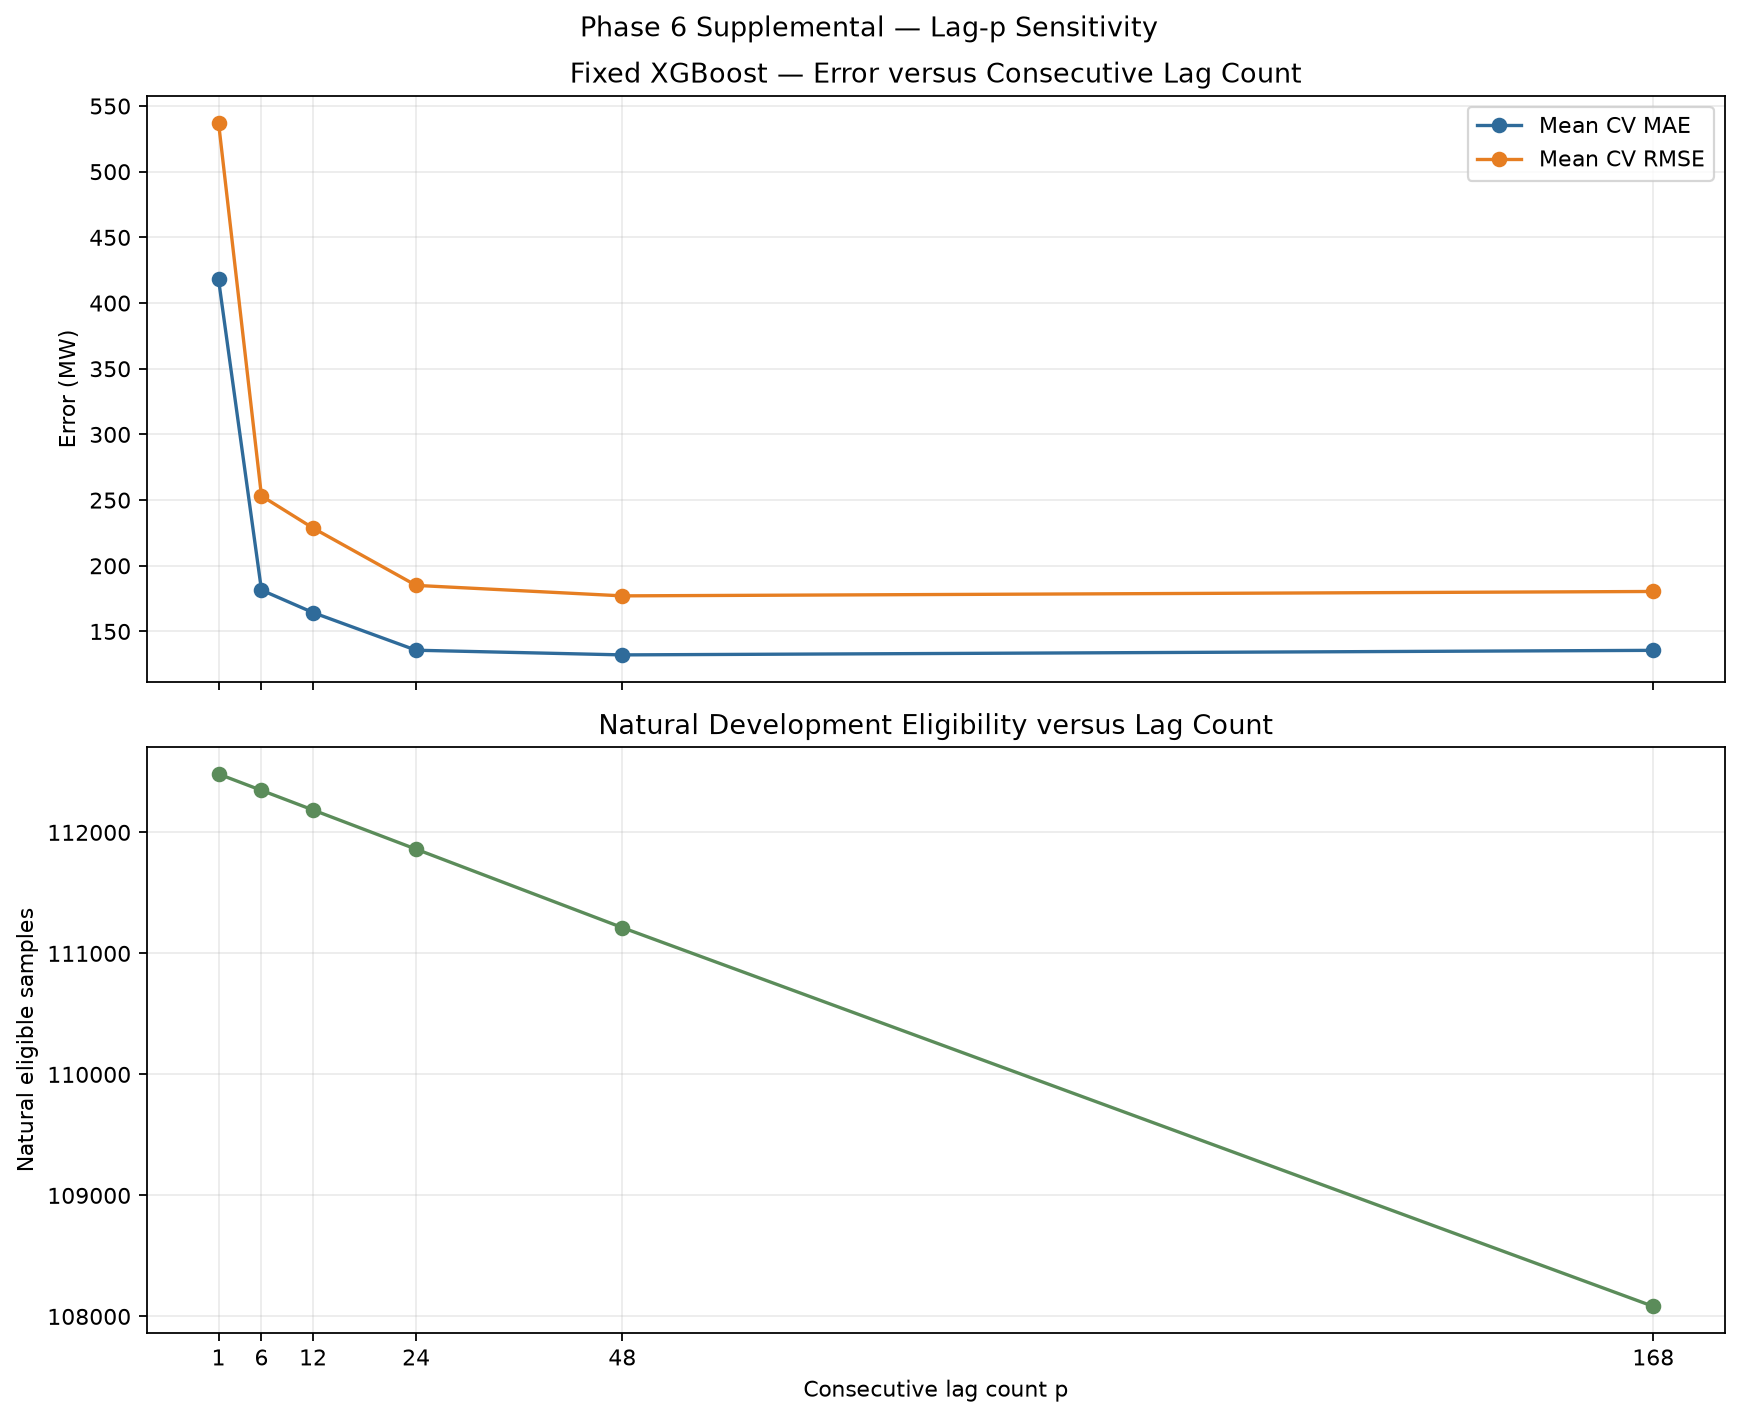

In [16]:
display(Markdown("#### Linear Regression và official XGBoost reference"))
display(DisplayImage(filename=str(phase_06_supplemental_model_figure_path)))
display(Markdown("#### Sensitivity khi tăng số lag liên tiếp p"))
display(DisplayImage(filename=str(phase_06_supplemental_lag_figure_path)))

**Kết quả:** XGBoost giảm CV MAE 20,845% so với Linear Regression; `p=48` tốt nhất trong các lag registry đã thử.

## Phase 7 — Final Evaluation

Đánh giá locked model trên historical holdout; không tuning lại.

In [17]:
phase_07_audit_path = project_root / "outputs/results/phase_07_evaluation_audit.json"
phase_07_one_step_metrics_path = project_root / "outputs/results/phase_07_one_step_metrics.json"
phase_07_recursive_metrics_path = project_root / "outputs/results/phase_07_recursive_metrics.json"
phase_07_one_step_predictions_path = project_root / "outputs/results/phase_07_one_step_predictions.csv"
phase_07_recursive_predictions_path = project_root / "outputs/results/phase_07_recursive_predictions.csv"
phase_07_full_figure_path = project_root / "outputs/figures/phase_07_one_step_full_holdout.png"
phase_07_diagnostic_figure_path = project_root / "outputs/figures/phase_07_one_step_first_14_days.png"
phase_07_recursive_figure_path = project_root / "outputs/figures/phase_07_recursive_error_by_horizon.png"
phase_07_paths = [
    phase_07_audit_path,
    phase_07_one_step_metrics_path,
    phase_07_recursive_metrics_path,
    phase_07_one_step_predictions_path,
    phase_07_recursive_predictions_path,
    phase_07_full_figure_path,
    phase_07_diagnostic_figure_path,
    phase_07_recursive_figure_path,
]
missing_phase_07_paths = [str(path) for path in phase_07_paths if not path.is_file()]
assert not missing_phase_07_paths, f"Missing Phase 7 artifacts: {missing_phase_07_paths}"
with phase_07_audit_path.open(encoding="utf-8") as file:
    phase_07_audit = json.load(file)
with phase_07_one_step_metrics_path.open(encoding="utf-8") as file:
    phase_07_one_step_metrics = json.load(file)
with phase_07_recursive_metrics_path.open(encoding="utf-8") as file:
    phase_07_recursive_metrics = json.load(file)
phase_07_one_step_predictions = pd.read_csv(phase_07_one_step_predictions_path)
phase_07_recursive_predictions = pd.read_csv(phase_07_recursive_predictions_path)
assert phase_07_audit["status"] == "PASS"
assert calculate_sha256(phase_07_one_step_predictions_path) == phase_07_audit["one_step"]["prediction_sha256"]
assert calculate_sha256(phase_07_one_step_metrics_path) == phase_07_audit["one_step"]["metrics_sha256"]
assert calculate_sha256(phase_07_recursive_predictions_path) == phase_07_audit["recursive"]["prediction_sha256"]
assert calculate_sha256(phase_07_recursive_metrics_path) == phase_07_audit["recursive"]["metrics_sha256"]
assert calculate_sha256(phase_07_full_figure_path) == phase_07_audit["figures"]["one_step_full_sha256"]
assert calculate_sha256(phase_07_diagnostic_figure_path) == phase_07_audit["figures"]["one_step_diagnostic_sha256"]
assert calculate_sha256(phase_07_recursive_figure_path) == phase_07_audit["figures"]["recursive_horizon_sha256"]
print("Presentation artifacts: Phase 7 PASS")

Presentation artifacts: Phase 7 PASS


In [18]:
phase_07_protocol = pd.DataFrame(
    [
        ["Holdout", phase_07_audit["opening_event"]["holdout_label"]],
        ["Locked model", phase_07_audit["locked_candidate"]],
        ["Development refit samples", phase_07_audit["development_refit_samples"]],
        ["One-step timestamps", phase_07_audit["one_step"]["common_eligible_rows"]],
        ["Recursive origins / horizon", f"{phase_07_audit['recursive']['eligible_common_origins']} / {phase_07_audit['recursive']['horizon_hours']}h"],
        ["Status", phase_07_audit["status"]],
    ],
    columns=["Evaluation protocol", "Kết quả"],
)
display(style_table(phase_07_protocol, formats={"Kết quả": lambda value: f"{value:,}" if isinstance(value, int) else value}, caption="Evaluation protocol"))

Evaluation protocol,Kết quả
Holdout,historical_re_evaluation_holdout
Locked model,xgboost_tuned
Development refit samples,"108,083"
One-step timestamps,"8,592"
Recursive origins / horizon,357 / 24h
Status,PASS


In [19]:
one_step_summary = pd.DataFrame(phase_07_one_step_metrics["candidate_metrics"])
one_step_summary = one_step_summary.rename(
    columns={
        "candidate": "Candidate",
        "mae": "MAE (MW)",
        "rmse": "RMSE (MW)",
        "n_observations": "Observations",
        "evaluation_start": "Start",
        "evaluation_end": "End",
    }
)
recursive_summary = pd.DataFrame(
    [
        [
            record["candidate"],
            record["pooled"]["pooled_mae"],
            record["pooled"]["pooled_rmse"],
            record["pooled"]["n_predictions"],
            record["pooled"]["n_origins"],
        ]
        for record in phase_07_recursive_metrics["candidate_metrics"]
    ],
    columns=["Candidate", "Pooled MAE (MW)", "Pooled RMSE (MW)", "Predictions", "Origins"],
)
def highlight_locked_model(row):
    style = SELECTED_ROW_STYLE
    return [style if row["Candidate"] == "xgboost_tuned" else "" for _ in row]
display(
    style_table(
        one_step_summary,
        formats={"MAE (MW)": "{:,.3f}", "RMSE (MW)": "{:,.3f}"},
        row_highlighter=highlight_locked_model,
        caption="One-step rolling observed-history metrics",
    )
)
display(
    style_table(
        recursive_summary,
        formats={"Pooled MAE (MW)": "{:,.3f}", "Pooled RMSE (MW)": "{:,.3f}"},
        row_highlighter=highlight_locked_model,
        caption="Recursive 24-hour pooled metrics",
    )
)

Candidate,MAE (MW),RMSE (MW),Observations,Start,End
persistence,408.979,520.940,8592,2017-08-03 00:00:00,2018-08-03 00:00:00
seasonal_naive_24,935.802,"1,212.274",8592,2017-08-03 00:00:00,2018-08-03 00:00:00
xgboost_tuned,102.841,137.929,8592,2017-08-03 00:00:00,2018-08-03 00:00:00


Candidate,Pooled MAE (MW),Pooled RMSE (MW),Predictions,Origins
persistence,"1,446.348","1,773.057",8568,357
seasonal_naive_24,934.655,"1,211.547",8568,357
xgboost_tuned,509.652,720.451,8568,357


### One-step Actual vs Predicted — 14 ngày đầu

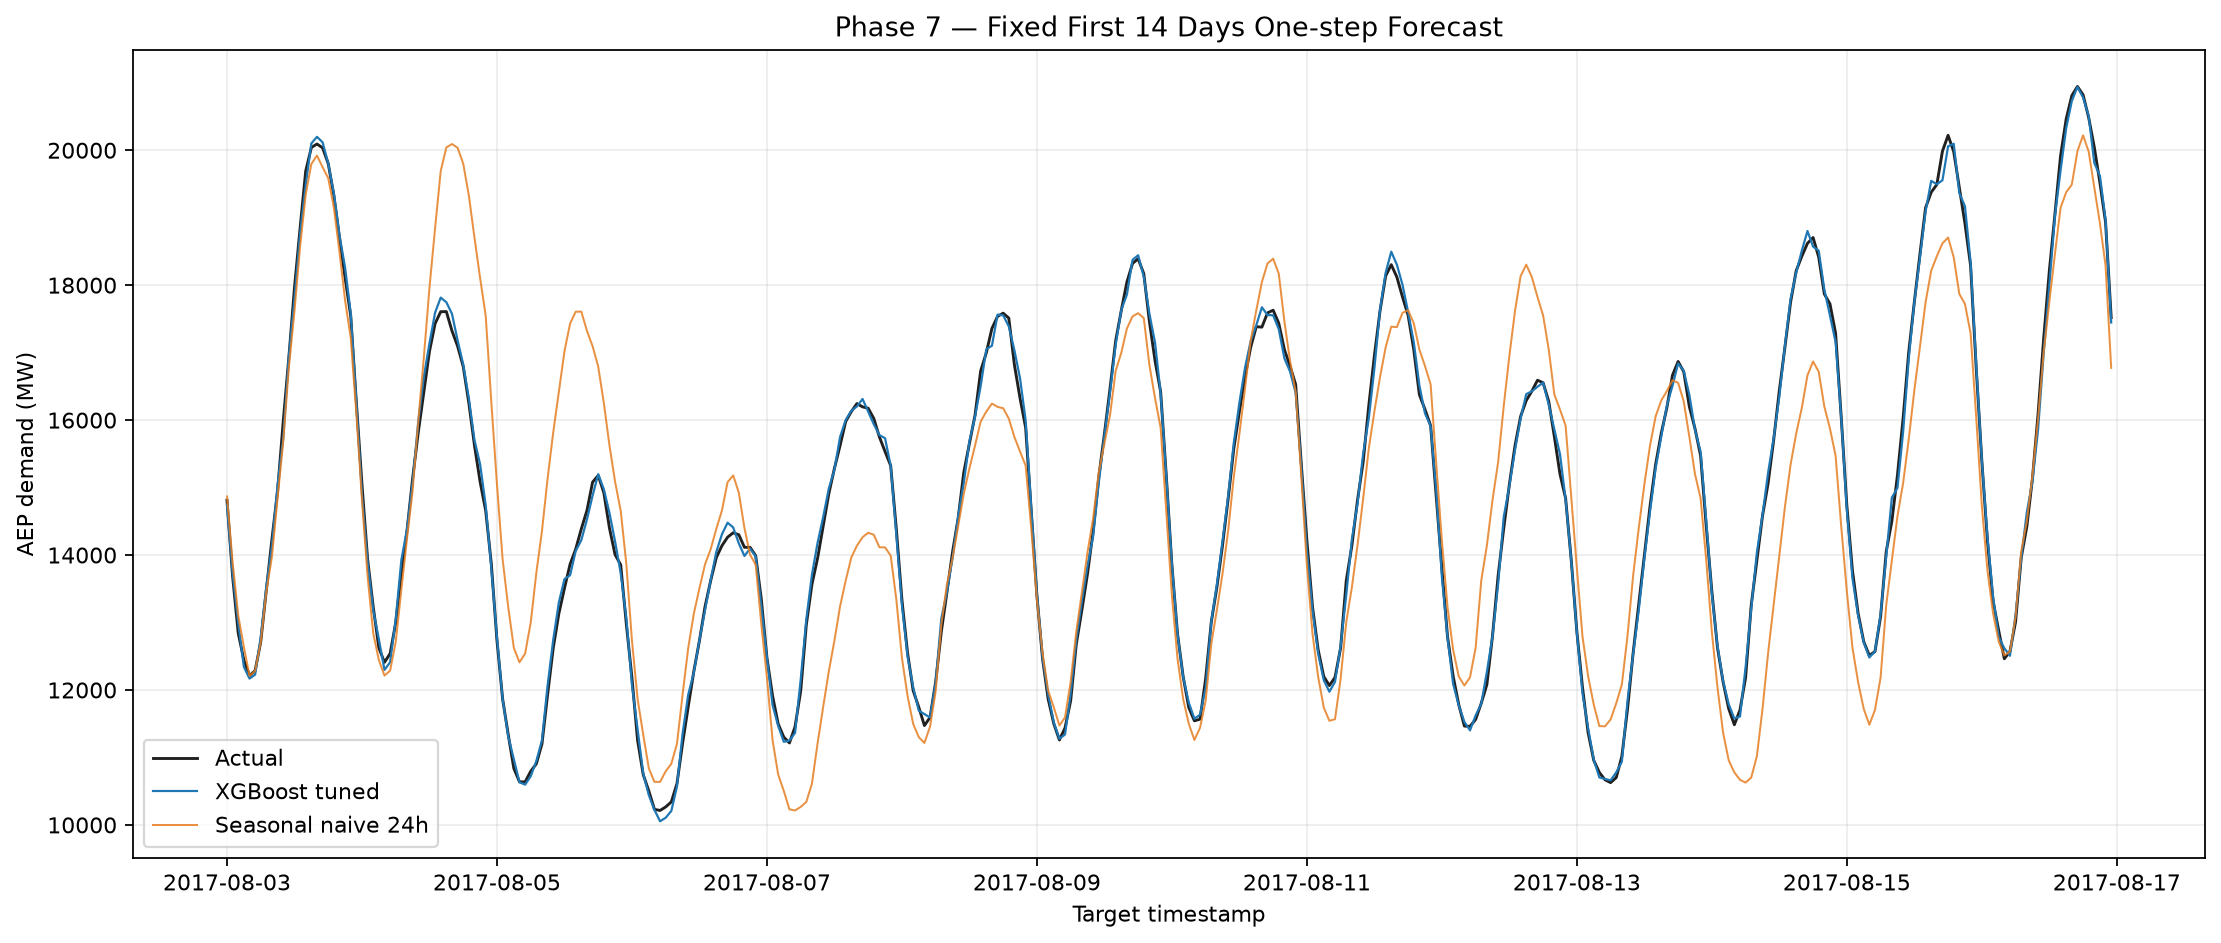

### Recursive 24-hour error by horizon

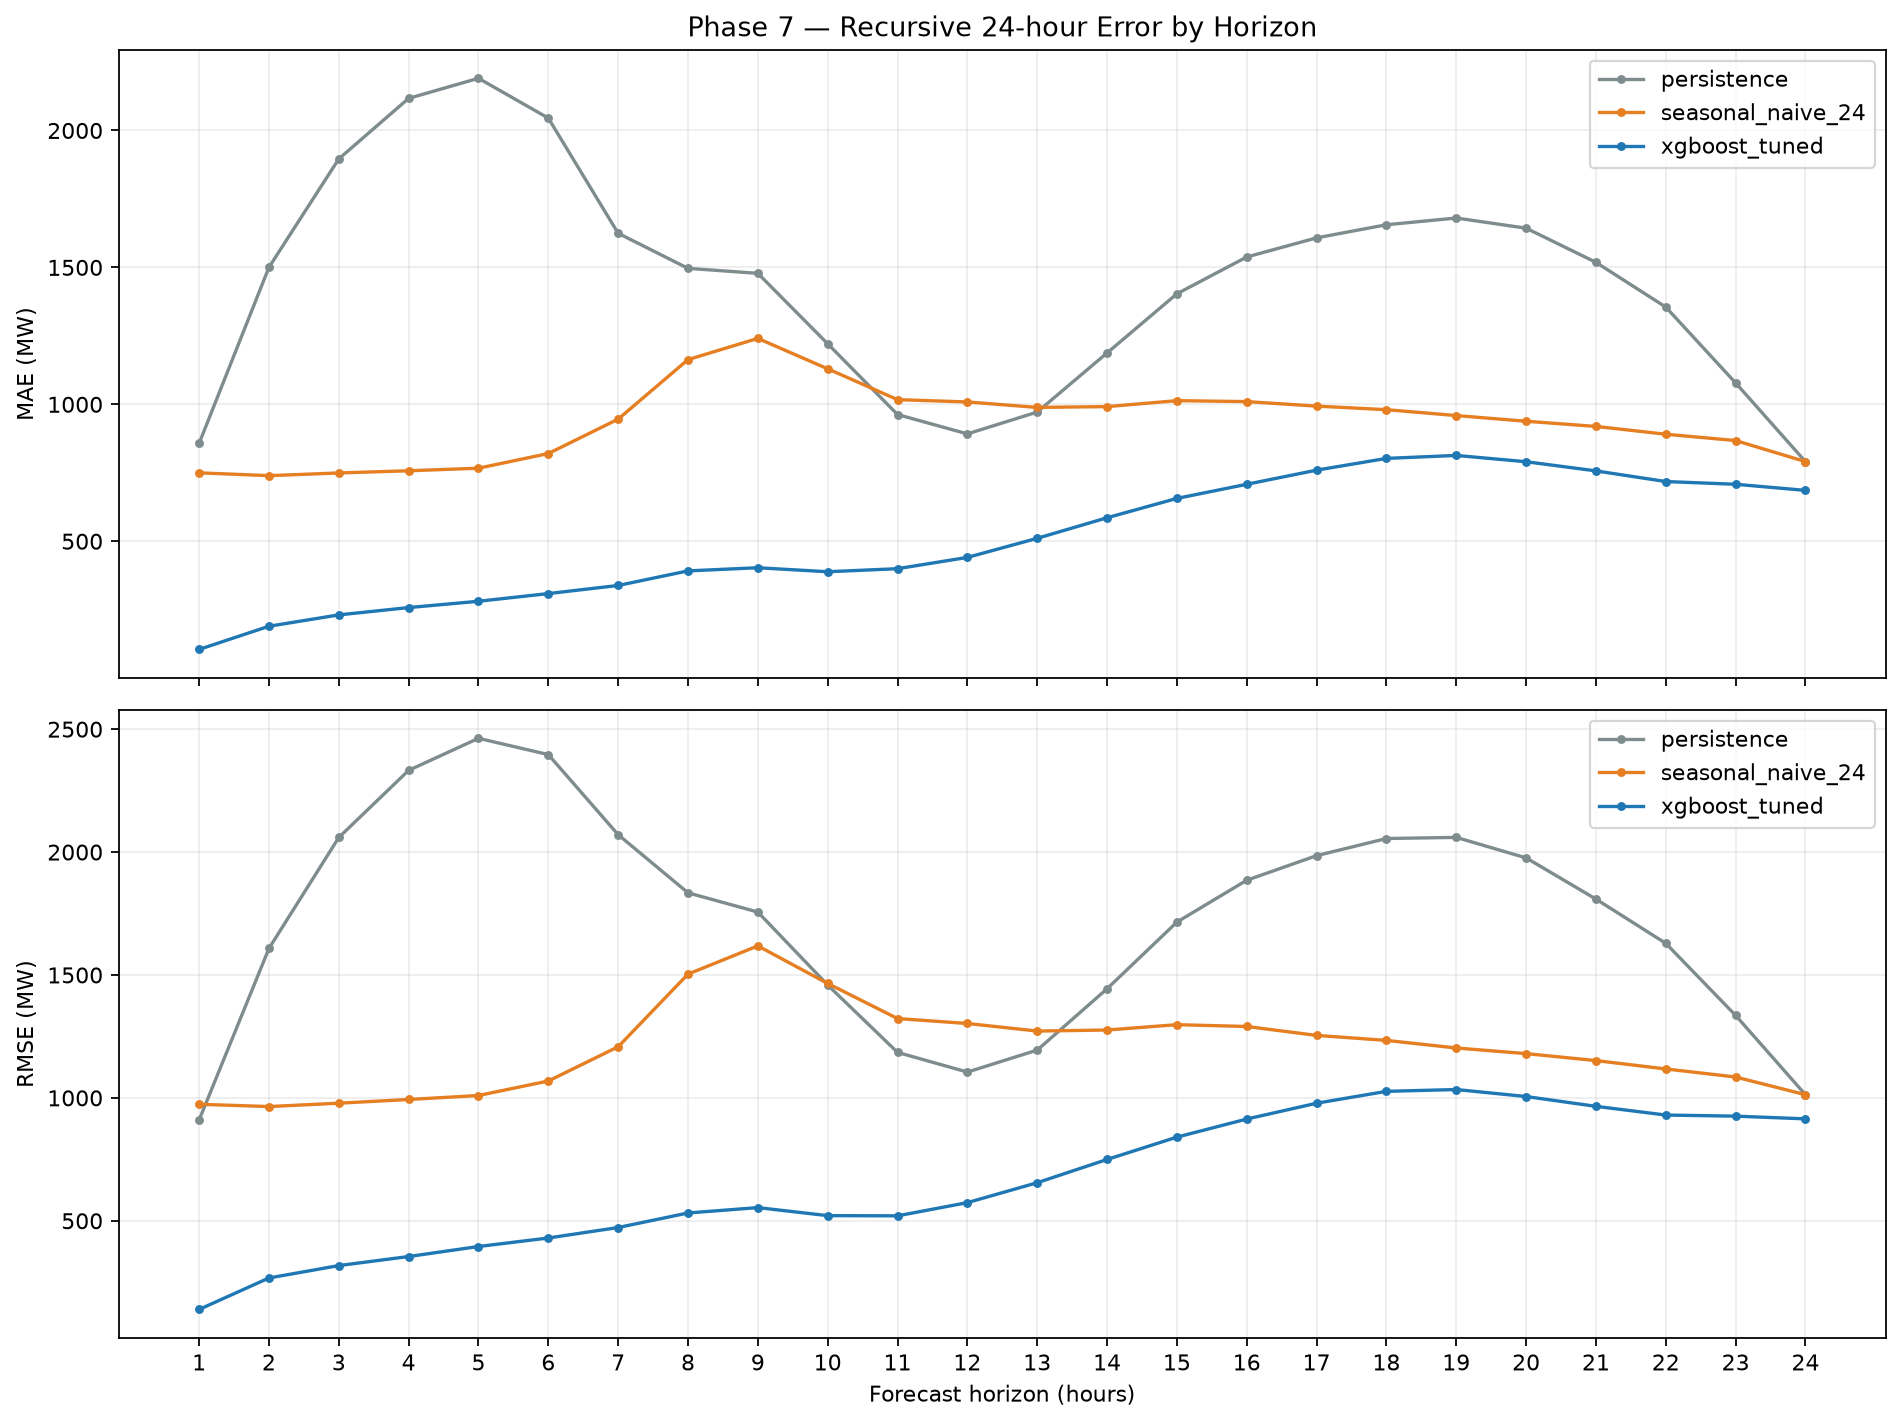

In [20]:
display(Markdown("### One-step Actual vs Predicted — 14 ngày đầu"))
display(DisplayImage(filename=str(phase_07_diagnostic_figure_path)))
display(Markdown("### Recursive 24-hour error by horizon"))
display(DisplayImage(filename=str(phase_07_recursive_figure_path)))

**Kết quả:** One-step MAE 102,841 MW; recursive 24h pooled MAE 509,652 MW — **PASS**.

## Phase 8 — Error Analysis and Interpretation

Phân tích official predictions, không thay đổi model lock.

In [21]:
phase_08_result_path = project_root / "outputs/results/phase_08_error_analysis.json"
phase_08_feature_path = project_root / "outputs/results/phase_08_feature_importance.csv"
phase_08_residual_figure_path = project_root / "outputs/figures/phase_08_residual_diagnostics.png"
phase_08_time_figure_path = project_root / "outputs/figures/phase_08_error_by_time.png"
phase_08_load_figure_path = project_root / "outputs/figures/phase_08_error_by_load_regime.png"
phase_08_importance_figure_path = project_root / "outputs/figures/phase_08_feature_importance.png"
phase_08_paths = [
    phase_08_result_path, phase_08_feature_path, phase_08_residual_figure_path,
    phase_08_time_figure_path, phase_08_load_figure_path, phase_08_importance_figure_path,
]
assert all(path.is_file() for path in phase_08_paths)
with phase_08_result_path.open(encoding="utf-8") as file:
    phase_08_result = json.load(file)
phase_08_feature_importance = pd.read_csv(phase_08_feature_path)
assert phase_08_result["status"] == "PASS"
assert phase_08_result["feature_importance"]["csv_sha256"] == calculate_sha256(phase_08_feature_path)
for figure_record in phase_08_result["figures"].values():
    assert calculate_sha256(project_root / figure_record["path"]) == figure_record["sha256"]

In [22]:
xgb_residual = next(
    item for item in phase_08_result["one_step"]["candidate_summaries"]
    if item["candidate"] == "xgboost_tuned"
)
phase_08_diagnostics = pd.DataFrame(
    [
        ["Observations", xgb_residual["n_observations"]],
        ["Mean error (MW)", xgb_residual["mean_error"]],
        ["MAE (MW)", xgb_residual["mae"]],
        ["RMSE (MW)", xgb_residual["rmse"]],
        ["Absolute error P95", xgb_residual["absolute_error_p95"]],
        ["Under-forecast rate", xgb_residual["under_forecast_rate"]],
        ["Residual ACF lag 1", phase_08_result["one_step"]["xgboost_residual_acf"][0]["autocorrelation"]],
    ],
    columns=["XGBoost diagnostic", "Kết quả"],
)
display(style_table(phase_08_diagnostics, formats={"Kết quả": lambda value: f"{value:,.3f}" if isinstance(value, float) else value}, caption="XGBoost diagnostic"))

XGBoost diagnostic,Kết quả
Observations,"8,592.000"
Mean error (MW),-1.192
MAE (MW),102.841
RMSE (MW),137.929
Absolute error P95,273.097
Under-forecast rate,0.514
Residual ACF lag 1,0.275


In [23]:
phase_08_top_features = phase_08_feature_importance.head(10).rename(columns={
    "rank": "Rank", "feature": "Feature", "feature_group": "Group", "normalized_gain": "Normalized gain",
})[["Rank", "Feature", "Group", "Normalized gain"]]
display(style_table(phase_08_top_features, formats={"Normalized gain": "{:.3%}"}, caption="Top 10 features by normalized gain"))

Rank,Feature,Group,Normalized gain
1,lag_1h,lag,89.224%
2,hour,calendar,1.772%
3,hour_cos,calendar,1.754%
4,lag_2h,lag,1.698%
5,lag_23h,lag,1.018%
6,is_weekend,calendar,0.858%
7,lag_24h,lag,0.616%
8,lag_3h,lag,0.507%
9,hour_sin,calendar,0.498%
10,month_cos,calendar,0.489%


### Residual distribution và exact-timestamp ACF

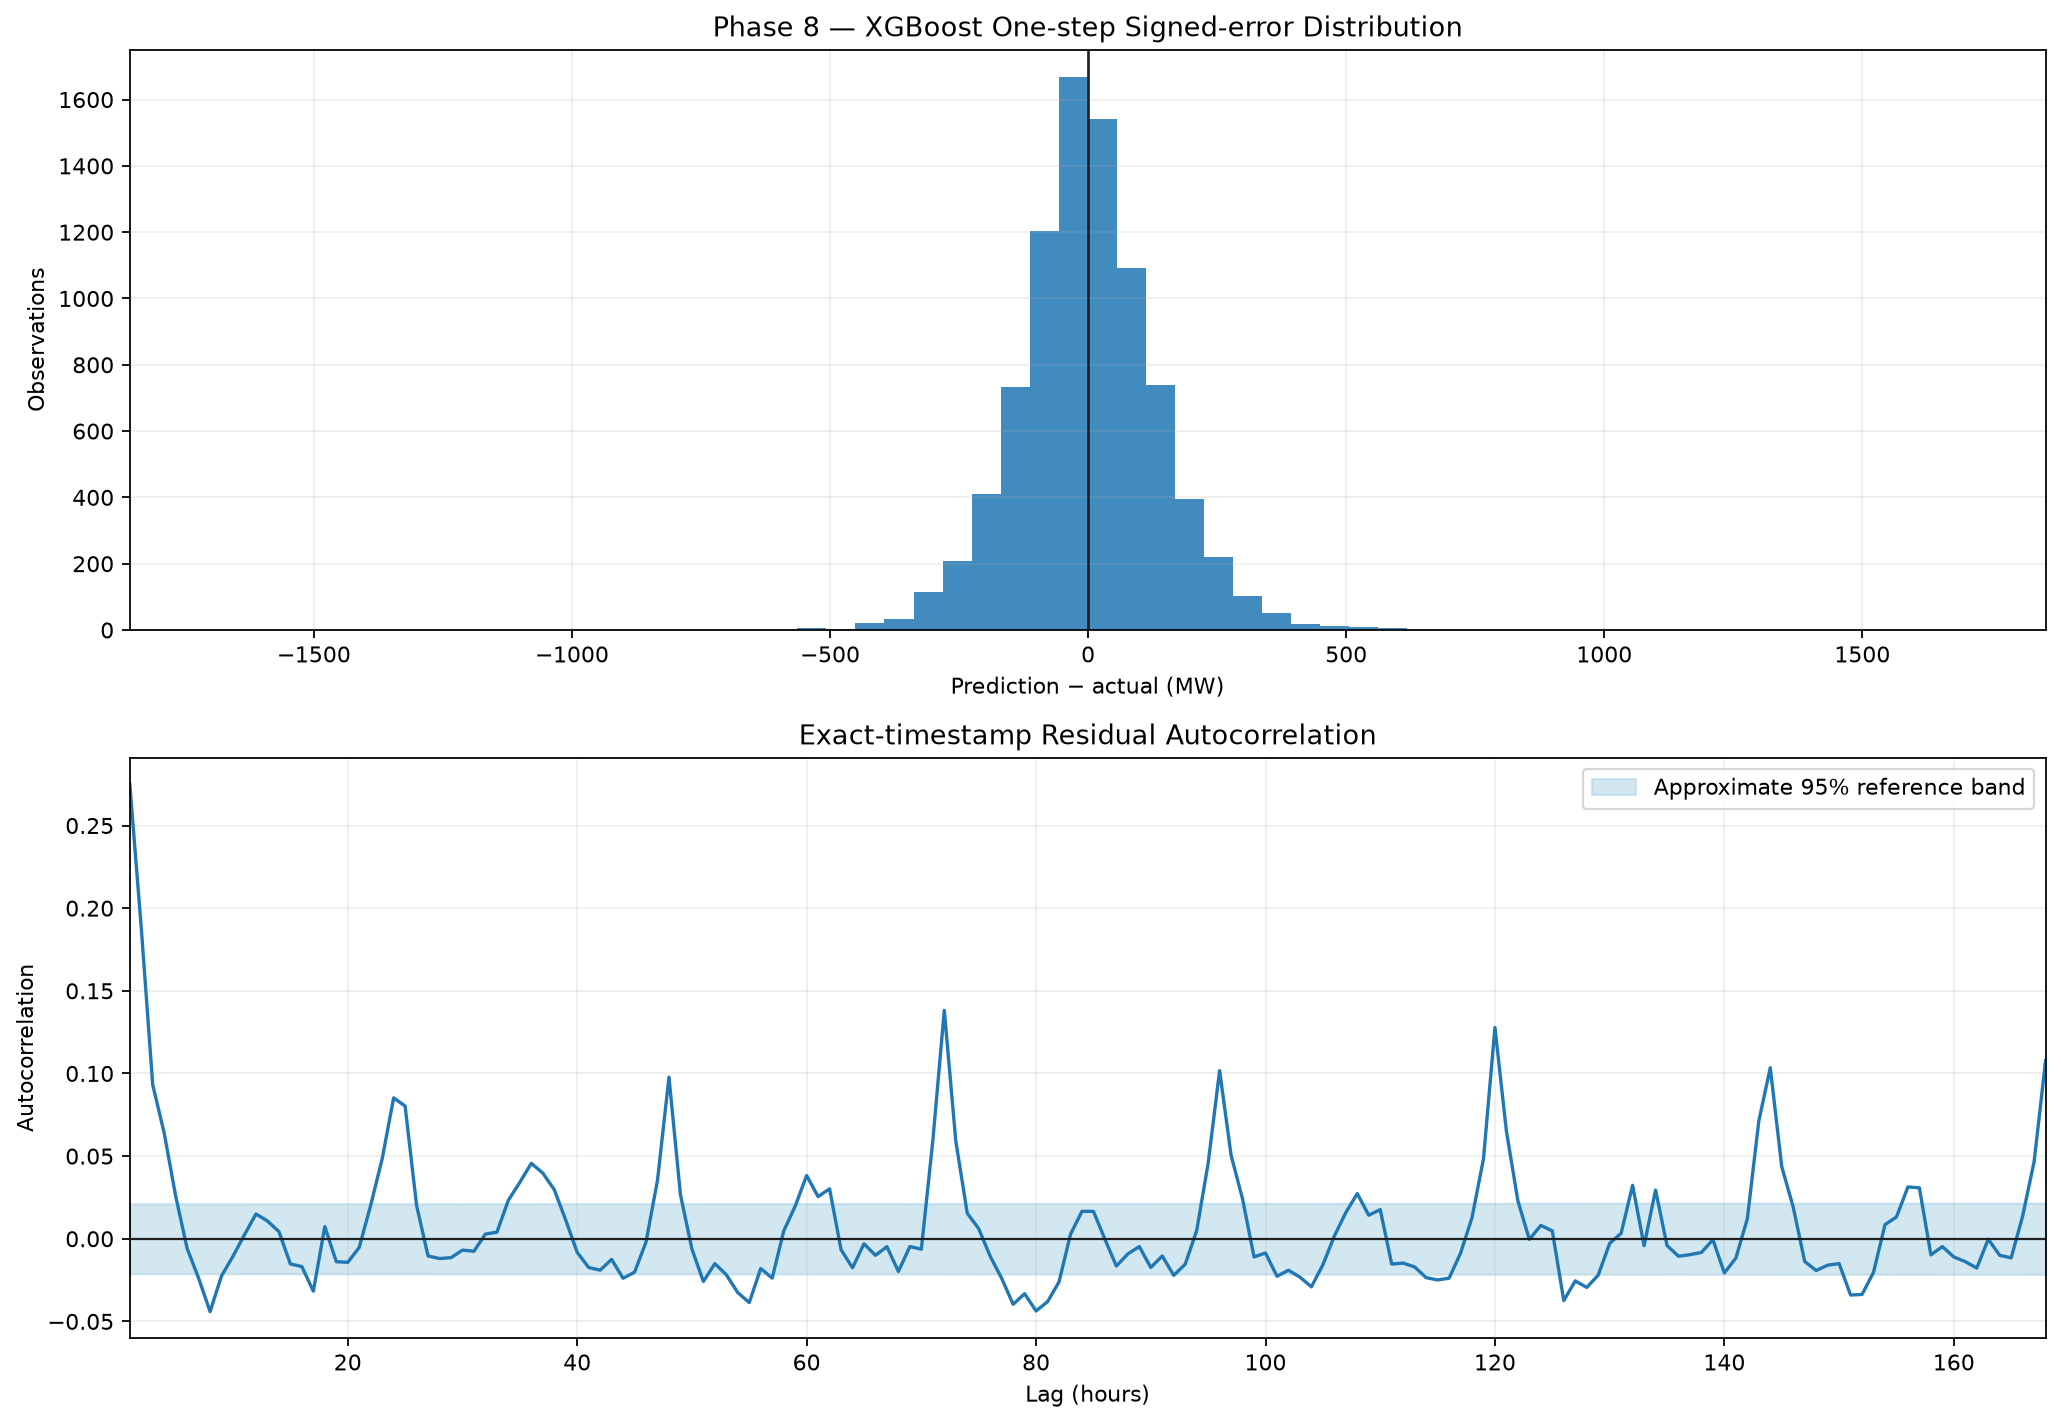

### One-step error theo time regime

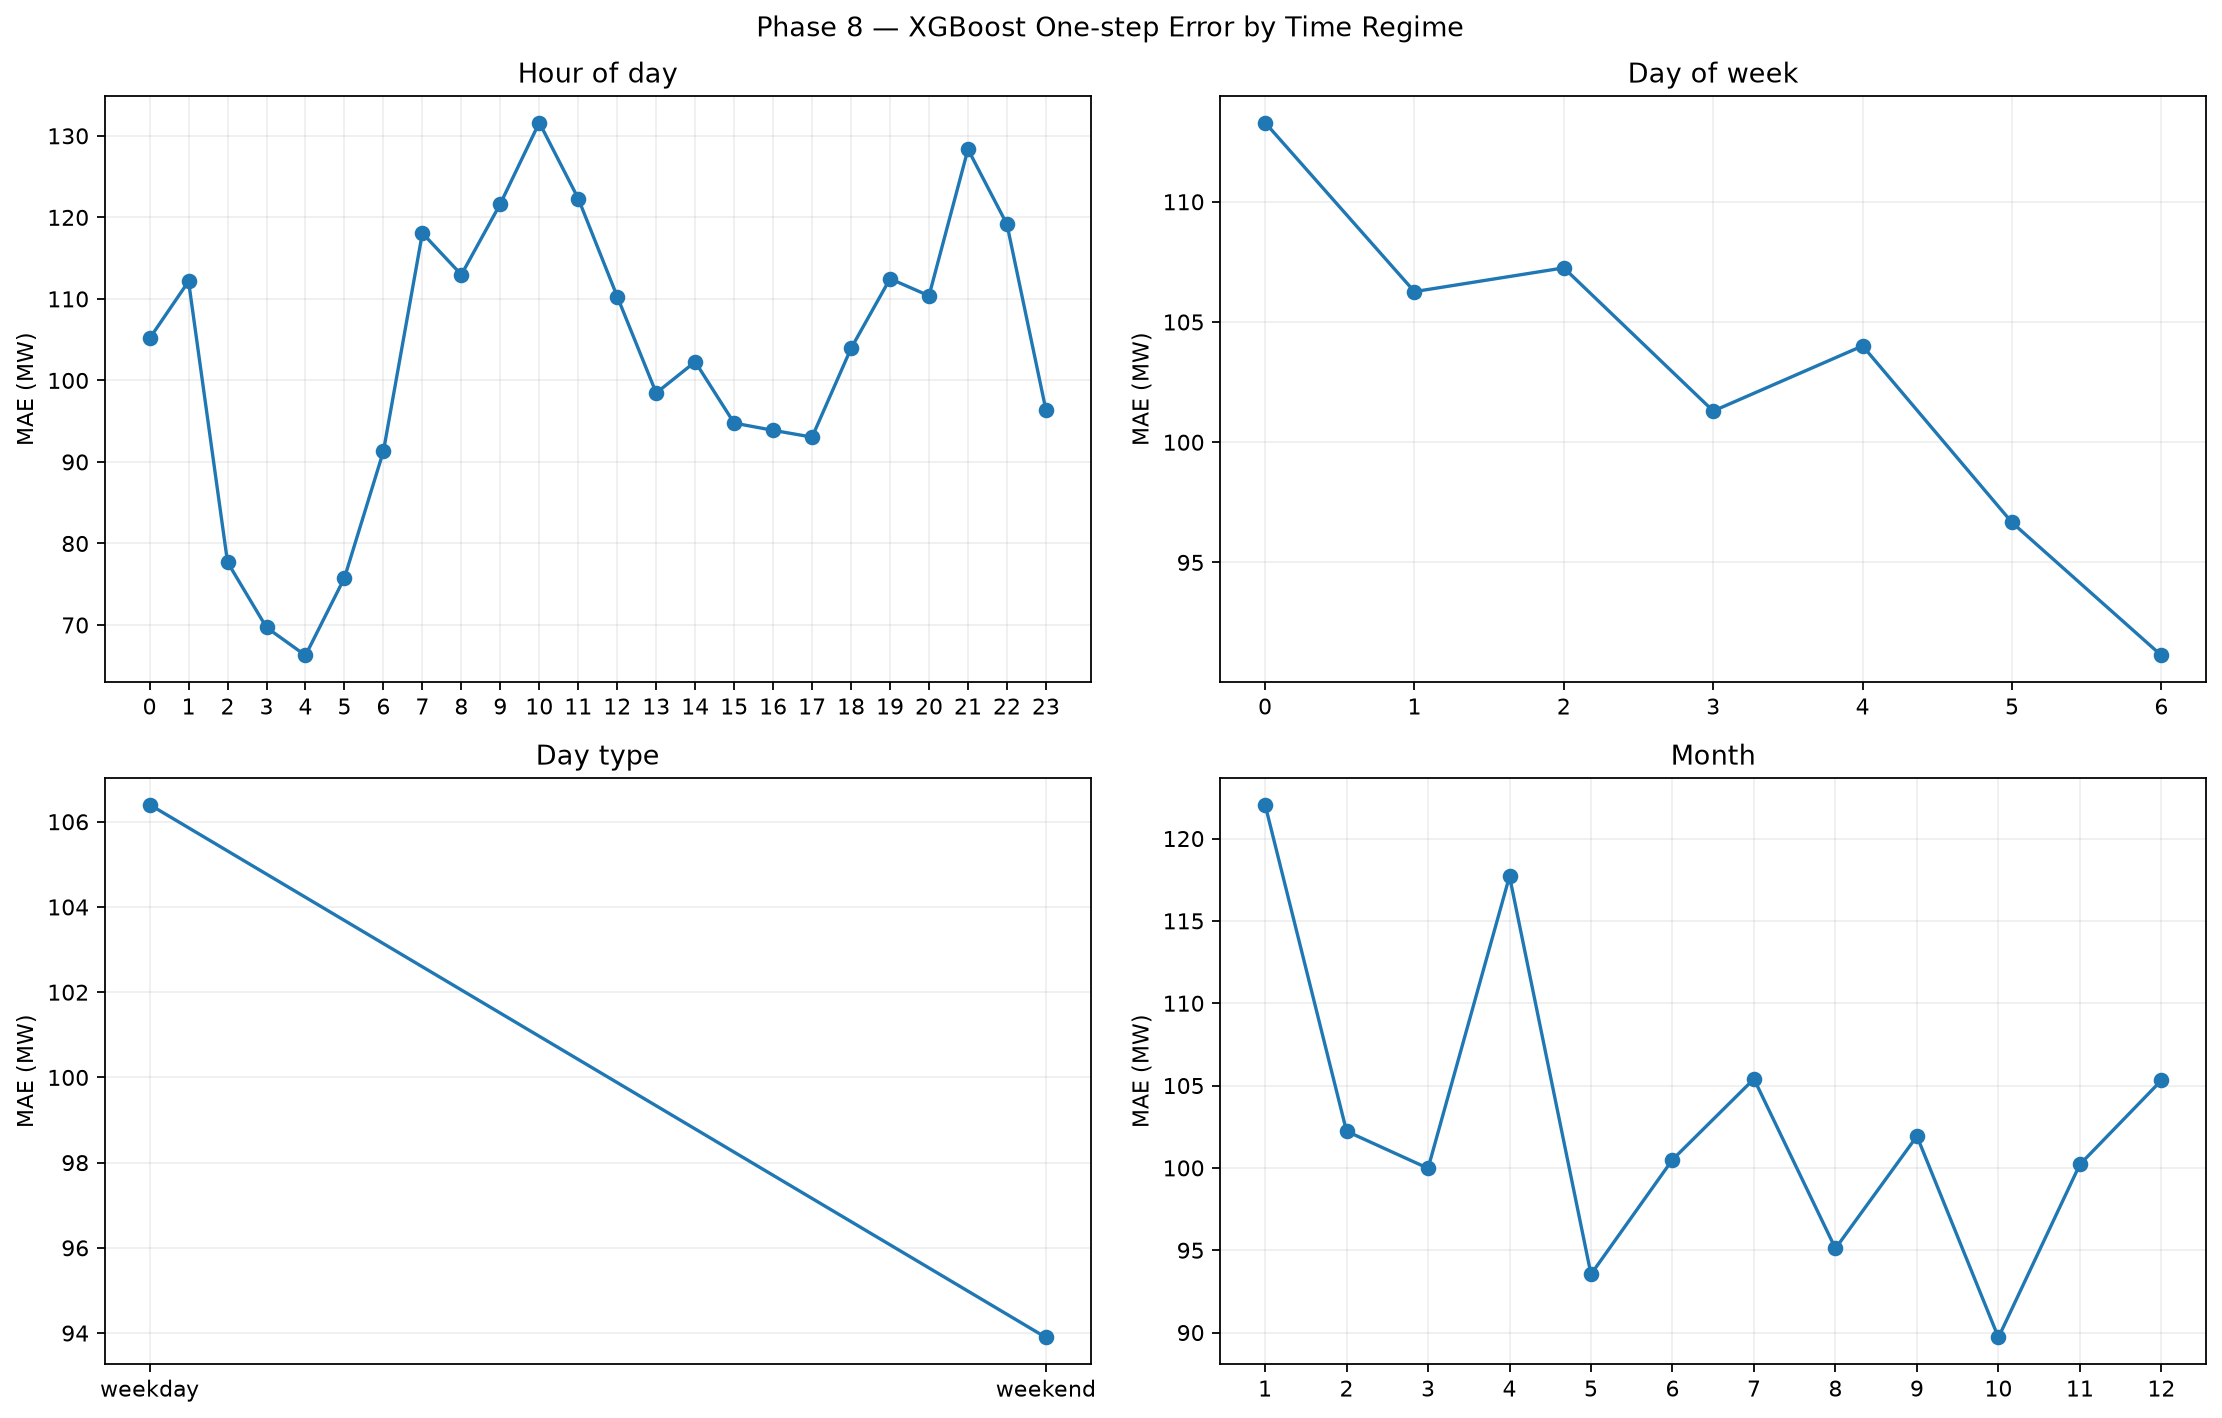

### One-step error theo actual-load quartile

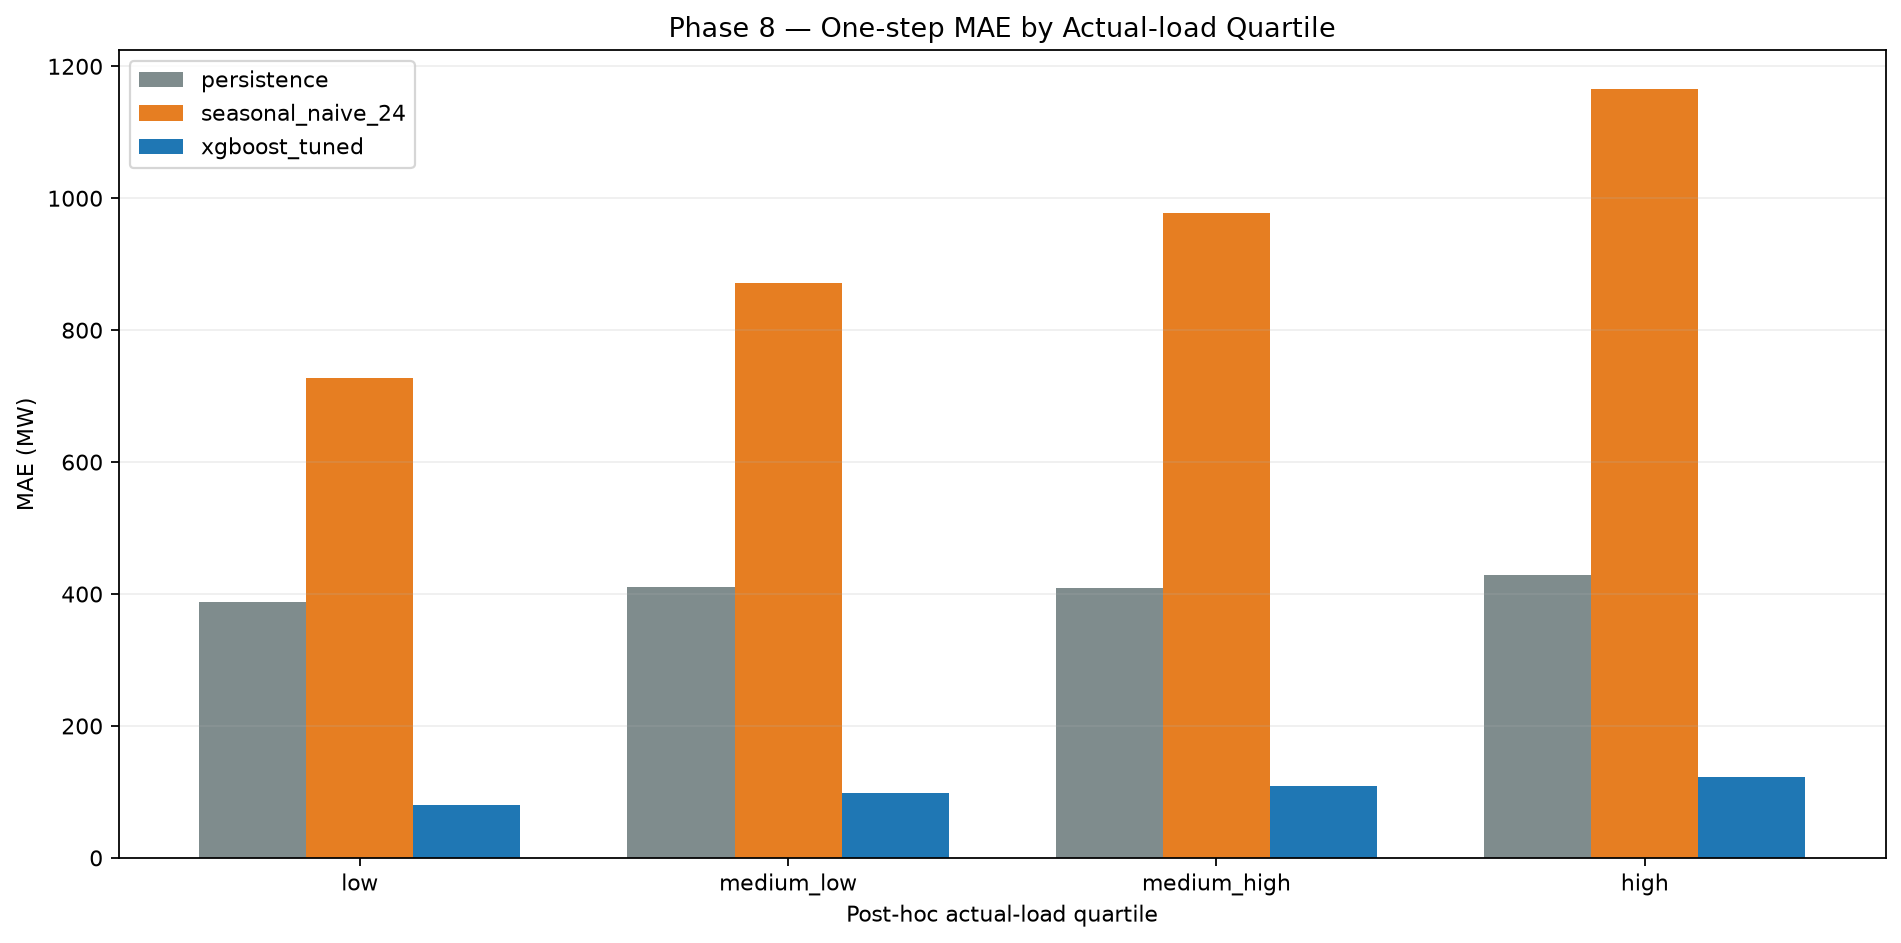

### Locked-XGBoost normalized gain importance

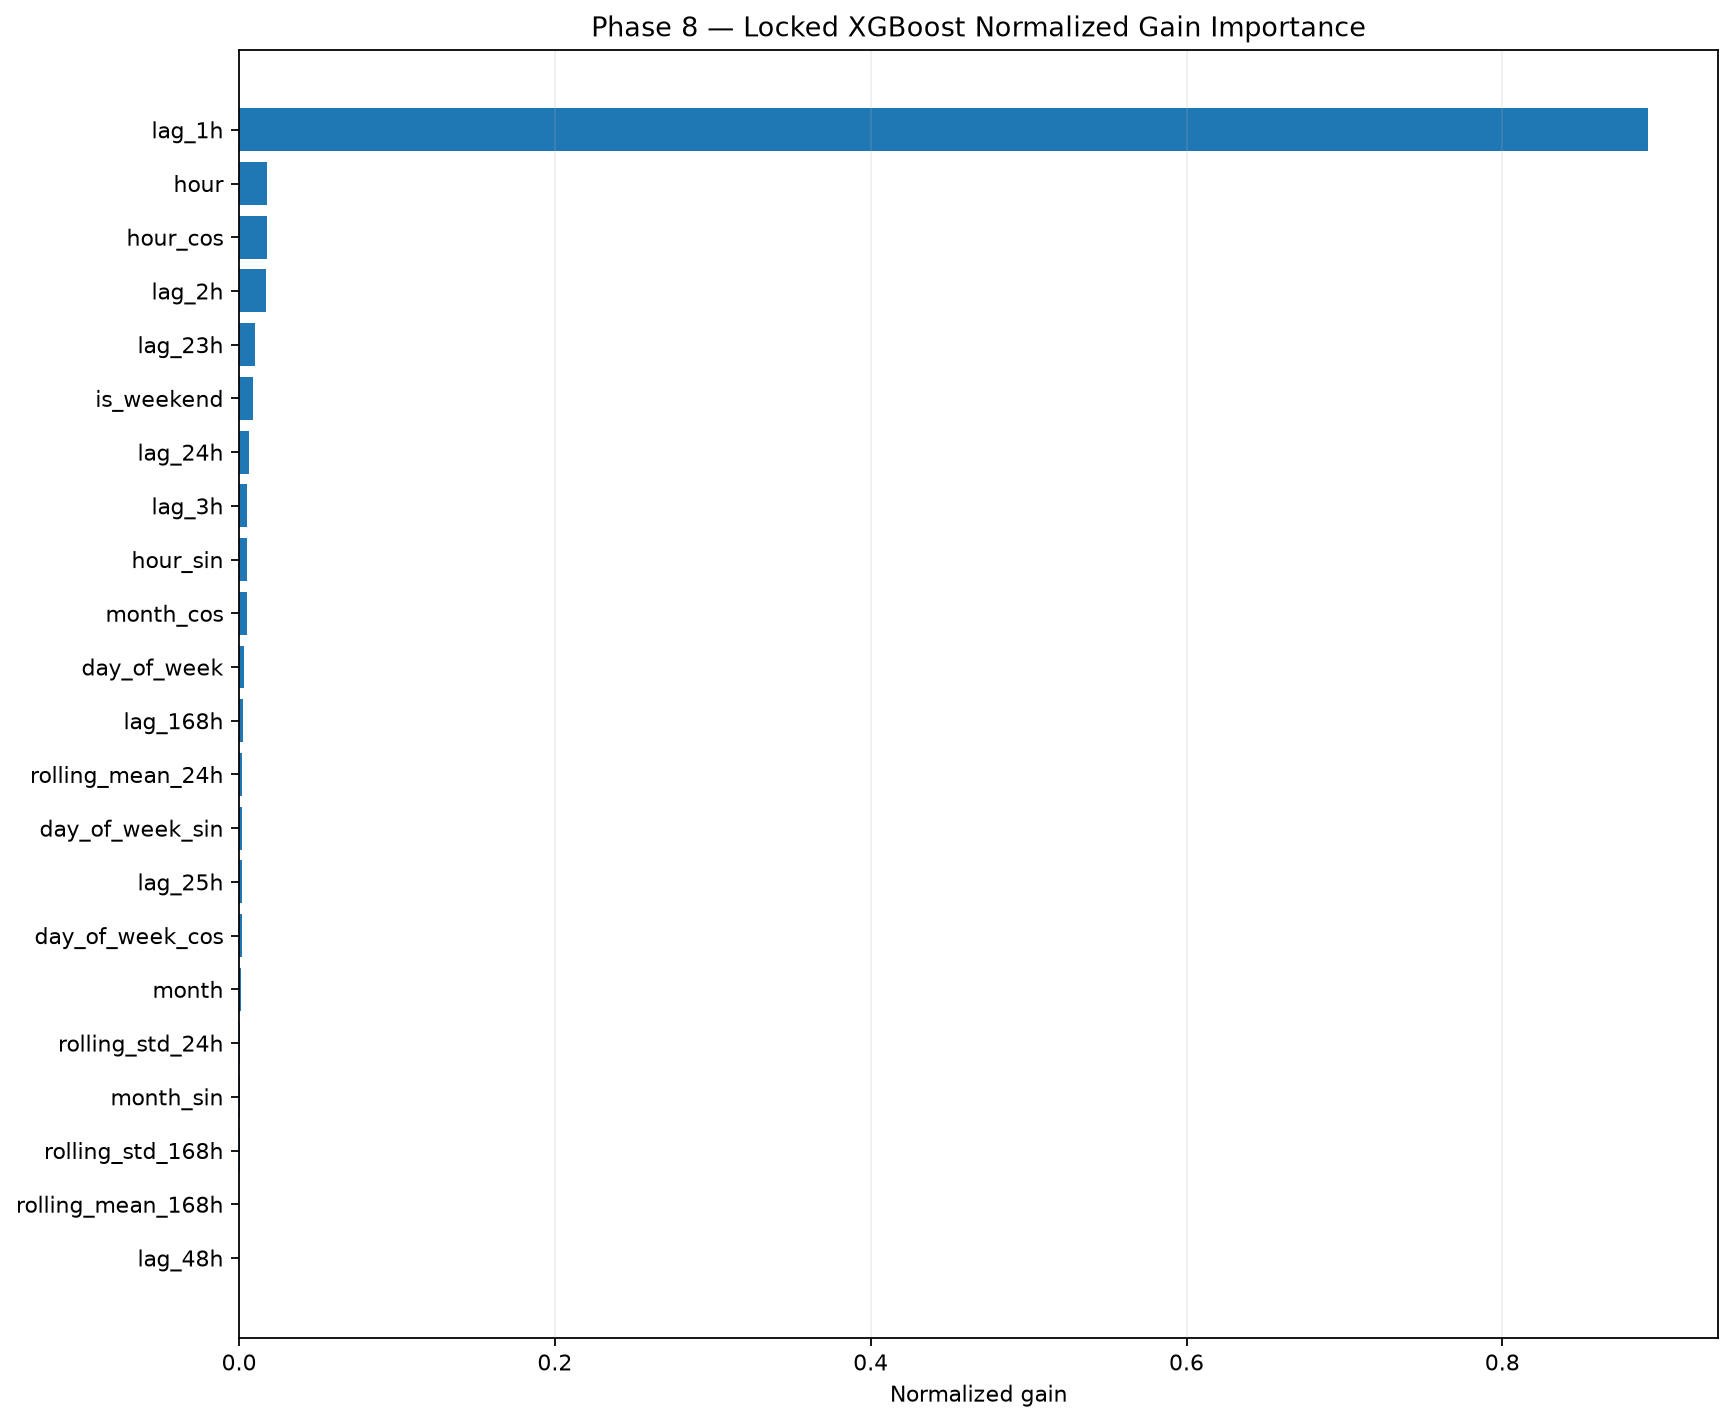

In [24]:
display(Markdown("### Residual distribution và exact-timestamp ACF"))
display(DisplayImage(filename=str(phase_08_residual_figure_path)))
display(Markdown("### One-step error theo time regime"))
display(DisplayImage(filename=str(phase_08_time_figure_path)))
display(Markdown("### One-step error theo actual-load quartile"))
display(DisplayImage(filename=str(phase_08_load_figure_path)))
display(Markdown("### Locked-XGBoost normalized gain importance"))
display(DisplayImage(filename=str(phase_08_importance_figure_path)))

**Pipeline validation:** **PASS** — official predictions, checksums và feature-importance artifact hợp lệ.

**Scientific finding:** Residual còn short-lag và daily temporal structure, nên chưa thể xem là white noise. Lag features chiếm phần lớn normalized gain; đây là limitation và không phải causal evidence.

## Phase 9 — Conclusion

Tổng hợp official evidence; không train hoặc predict lại.

In [25]:
phase_09_conclusion_path = project_root / "outputs/results/phase_09_final_conclusion.json"
phase_09_contract_path = project_root / "config/final_conclusion.json"
assert phase_09_conclusion_path.is_file() and phase_09_contract_path.is_file()
with phase_09_conclusion_path.open(encoding="utf-8") as file:
    phase_09_conclusion = json.load(file)
with phase_09_contract_path.open(encoding="utf-8") as file:
    phase_09_contract = json.load(file)
assert phase_09_conclusion["status"] == "PASS"
assert phase_09_conclusion["official_model"]["selected_candidate"] == "xgboost_tuned"
for name, record in phase_09_contract["upstream"].items():
    assert phase_09_conclusion["upstream_sha256"][name] == record["sha256"]

In [26]:
one_step_final = phase_09_conclusion["final_evaluation"]["one_step"]["xgboost_conclusion"]
recursive_final = phase_09_conclusion["final_evaluation"]["recursive_24h"]["xgboost_conclusion"]
final_metrics = pd.DataFrame(
    [
        ["One-step hourly", one_step_final["mae"], one_step_final["rmse"], f"{one_step_final['n_observations']:,} timestamps"],
        ["Recursive 24-hour pooled", recursive_final["pooled_mae"], recursive_final["pooled_rmse"], f"{recursive_final['n_origins']:,} origins / {recursive_final['n_predictions']:,} predictions"],
    ],
    columns=["Protocol", "MAE (MW)", "RMSE (MW)", "Population"],
)
display(
    style_table(
        final_metrics,
        formats={"MAE (MW)": "{:,.3f}", "RMSE (MW)": "{:,.3f}"},
        caption="Kết quả đánh giá cuối cùng",
    )
)
print(f"Recursive hardest horizon: {recursive_final['hardest_horizon_by_mae']} — MAE {recursive_final['hardest_horizon_mae']:,.3f} MW")

Protocol,MAE (MW),RMSE (MW),Population
One-step hourly,102.841,137.929,"8,592 timestamps"
Recursive 24-hour pooled,509.652,720.451,"357 origins / 8,568 predictions"


Recursive hardest horizon: 19 — MAE 813.359 MW


In [27]:
claim_summary = pd.DataFrame(
    [
        ["Holdout", "Historical re-evaluation; không claim truly unseen"],
        ["Residual white noise", phase_09_conclusion["error_interpretation"]["residual_white_noise_claim_allowed"]],
        ["ARIMA benchmark", phase_09_conclusion["assignment_answers"]["xgboost_vs_arima"]["arima_empirically_benchmarked"]],
        ["Production readiness", phase_09_conclusion["claim_boundary"]["production_readiness_claimed"]],
        ["External generalization", phase_09_conclusion["claim_boundary"]["external_generalization_claimed"]],
        ["Status", phase_09_conclusion["status"]],
    ],
    columns=["Claim boundary", "Kết quả"],
)
display(style_table(claim_summary, caption="Giới hạn của kết luận"))

Claim boundary,Kết quả
Holdout,Historical re-evaluation; không claim truly unseen
Residual white noise,False
ARIMA benchmark,False
Production readiness,False
External generalization,False
Status,PASS


### Kết luận

- `xgboost_tuned` có development CV MAE thấp nhất trong official candidate registry và tốt hơn Persistence, Seasonal Naive 24h trên Historical Re-evaluation Holdout.
- One-step hourly forecasting là kết quả chính; recursive 24-hour vẫn tốt hơn hai baselines nhưng error tăng theo horizon.
- Trong post-hoc development comparison trên cùng 42.413 validation samples, tuned XGBoost giảm MAE khoảng 20,845% so với Linear Regression.
- Lag sensitivity cải thiện mạnh đến `p=24`, tốt nhất quan sát tại `p=48`, rồi giảm chất lượng tại `p=168`; tăng số lag không luôn cải thiện model.
- `lag_1h` là lag quan trọng nhất theo normalized XGBoost gain; gain là model-specific association, không phải causal importance.
- XGBoost phù hợp khi có nhiều lag/rolling/calendar features và nonlinear interactions. ARIMA có thể phù hợp hơn với cấu trúc tuyến tính, stationary và nhu cầu statistical intervals; project chưa benchmark ARIMA nên không có superiority claim.
- Historical Re-evaluation Holdout không phải truly unseen test set. Project chưa có prediction interval, external validation hoặc drift monitoring và không tuyên bố production readiness.